# MSM analysis of the phosphorylation cycle

Estimates the cycle affinity $\Delta\mu_{cycle}$ from Markov state models of the enzyme/substrate states.

1. **Build state trajectories**: distances, phosphorylation and state trajectories from the simulations
2. **Single enzyme, 4 states** (CK1δ or PP3): ITS, CK test, $\Delta\mu$ vs lag time, $\Delta\mu$ vs $\Delta\mu_p$
3. **CK1δ + PP3, 6 states**: same analysis for the kinase/phosphatase cycle
4. **Legacy datasets** (HPS ser10, CALVADOS3 8 states, lost cycles, contact statistics), whose data are no longer on `/localscratch`

All `hpa.msm` estimators take 0-based state trajectories: `load_states` returns `states - 1`.

# Setup

In [1]:
import os
import sys

import numpy as np
import networkx as nx
from matplotlib import pyplot as plt
from matplotlib.patches import FancyArrowPatch
from scipy.optimize import curve_fit
from tqdm import tqdm
import MDAnalysis.analysis.distances  # used by hpa.trajectory.create_distance_file
import deeptime.markov as markov
from deeptime.plots import plot_implied_timescales, plot_ck_test
from deeptime.util.validation import implied_timescales

module_path = os.path.abspath('src')    # run the notebooks from the repository folder
if module_path not in sys.path:
    sys.path.insert(0, module_path)
from hpa.paths import SIM, AN, PL, INPUT_STATS, REPO, STYLES   # data locations (set HPA_DATA_ROOT to use another copy)

import hpa.msm
import hpa.plots
import hpa.stats
import hpa.trajectory
from hpa.stats import linear

plt.style.use(STYLES + 'corr_plot.mplstyle')

/localscratch/zippoema/lib/python_envs/hpa_env/lib/python3.11/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
/localscratch/zippoema/lib/python_envs/hpa_env/lib/python3.11/site-packages/MDAnalysis/topology/TPRParser.py:160: DeprecationWarning: 'xdrlib' is deprecated and slated for removal in Python 3.13
  import xdrlib


In [18]:
path_sims = SIM + 'cycle_single_TDP43/'
path_an = AN + 'cycle_single_TDP43/'
path_pl = PL + 'cycle_single_TDP43/'

KB = hpa.msm.KB    # kJ/(mol K)
kT = 200 * KB      # all friction01 simulations run at 200 K
RDUMP = 5          # one frame every RDUMP*10^3 MD steps
STEP = RDUMP * 1000
N_SIMS = 5
THERM = 1000       # frames discarded at the start of every simulation
N_TDP = 154        # beads of the TDP-43 LCD

SYSTEMS = {
    'pp3': dict(folder='simple-ness_pp3_masspSer_fr01', sern=18, npser='',
                enzymes='1-pp3', enzfile='com-pp3',
                dir_tag='200K_5k_mpSer_fr01', file_tag='200K_5k_mpSer_fr01',
                enz_ids=[[153+92, 153+94, 153+120, 153+152, 153+283]],
                dmus=['-2.5', '0', '+2.5', '+5']),
    'ck1d': dict(folder='simple-ness_ck1d_masspSer_fr01', sern=19, npser='-5pser',
                 enzymes='1-ck1d-open', enzfile='com-ck1d-open',
                 dir_tag='200K_5k_mpSer_fr01', file_tag='200K_5k_mpSer_fr01',
                 enz_ids=[[300, 301, 302]],
                 dmus=['-5', '-2.5', '0']),
    # dmu = '{dmu_k}_{dmu_p}'; distance columns: [:154] CK1d, [154:] PP3
    'ck1d_pp3': dict(folder='ness_ck1d_pp3_masspSer_fr01', sern=19, npser='-5pser',
                     enzymes='1-ck1d-open_1-pp3', enzfile='com-ck1d-open_com-pp3',
                     dir_tag='sp_repel_mpSer_fr01', file_tag='200K_5k_sp_repel_mpSer_fr01',
                     enz_ids=[[300, 301, 302], [445+92, 445+94, 445+120, 445+152, 445+283]],
                     dmus=['0_0', '-5_0', '-5_+2.5', '-10_0']),
}

## Helper functions

In [19]:
def file_prefix(base, system, dmu, label):
    '''Path prefix of a simulation file (label='sim{n}') or of a figure (label=plot name).

    Example: file_prefix(path_an, 'pp3', '+2.5', 'sim1') + '_states.txt'
    '''
    sy = SYSTEMS[system]
    tdp = f"ser{sy['sern']}_dmu{dmu}_1-tdp43{sy['npser']}"
    return (f"{base}{sy['folder']}/sim_{tdp}_{sy['enzymes']}_{sy['dir_tag']}/"
            f"{label}_{tdp}_{sy['enzfile']}_CAL3_{sy['file_tag']}")


def summary_prefix(system, name):
    '''Figure prefix for plots that combine several Delta mu values.'''
    sy = SYSTEMS[system]
    return f"{path_pl}{sy['folder']}/{name}_ser{sy['sern']}_1-tdp43{sy['npser']}_{sy['enzfile']}_CAL3_{sy['file_tag']}"


def savefig(prefix):
    for ext in ('pdf', 'png'):
        plt.savefig(f'{prefix}.{ext}', dpi=1200)


def load_state_list(system, dmu, vampnet='', therm=THERM, n_sims=N_SIMS):
    '''0-based state trajectory of every simulation, without the first `therm` frames.'''
    return [np.loadtxt(file_prefix(path_an, system, dmu, f'sim{s}') + f'_states{vampnet}.txt').astype(int)[therm:] - 1
            for s in range(1, n_sims + 1)]


def load_states(system, dmu, vampnet='', therm=THERM, n_sims=N_SIMS):
    '''All simulations joined in a single 0-based trajectory.'''
    return hpa.msm.concatenate_trajectories(load_state_list(system, dmu, vampnet, therm, n_sims))

In [20]:
def bayesian_msms(dtraj, lagtimes, n_steps=2**8, reversible=False):
    '''Bayesian MSMs at every lag time (input of the implied-timescale plot).'''
    models = []
    for lag in tqdm(lagtimes):
        counts = markov.TransitionCountEstimator(lagtime=lag, count_mode='effective').fit_fetch(dtraj)
        models.append(markov.msm.BayesianMSM(n_samples=100, n_steps=n_steps, reversible=reversible).fit_fetch(counts))
    return models


def plot_its(models, xlim, xlabel=rf'lag time [steps {RDUMP}$\times 10^3$]',
             ylabel=rf'timescale [steps {RDUMP}$\times 10^3$]', save=None):
    fig, ax = plt.subplots(1, 1, figsize=(3.2, 2))
    plot_implied_timescales(implied_timescales(models), ax=ax, show_mle=False, sample_confidence=.68)
    ax.set_yscale('log')
    ax.set_xlabel(xlabel)
    ax.set_ylabel(ylabel)
    ax.set_xlim(*xlim)
    if save is not None:
        savefig(save)


def plot_ck_grid(x, predicted, estimated, estimated_err, figsize, xticks, legend_loc,
                 xlabel=r'lag time [steps $\times 10^4$]', text_x=2, fontsize=6, save=None):
    '''Grid of predicted vs estimated transition probabilities (output of hpa.msm.ck_test).'''
    n = predicted.shape[1]
    with plt.rc_context({'axes.titlesize': 8, 'axes.labelsize': 10, 'xtick.labelsize': 9, 'ytick.labelsize': 9}):
        fig, ax = plt.subplots(n, n, figsize=figsize, sharex=True, sharey=True)
        plt.yticks([0.0, 0.5, 1.0], [0.0, 0.5, 1.0])
        plt.xticks(xticks, xticks)

        for i in range(n):
            for j in range(n):
                a = ax[i, j]
                a.plot(x, predicted[:, i, j], 'k', linewidth=0.7, label='predicted')
                a.plot(x, estimated[:, i, j], '--r', linewidth=0.7, label='estimated')
                a.fill_between(x, estimated[:, i, j] - estimated_err[:, i, j], estimated[:, i, j] + estimated_err[:, i, j],
                               alpha=0.25, color='tab:red', linewidth=0.2)
                a.set_ylim(-0.1, 1.1)
                a.text(text_x, 0.85, f'{i+1}->{j+1}', fontsize=fontsize)

        # axis labels and legend on single panels, shifted to the centre of the grid
        ax[n - 1, n // 2 - 1].set_xlabel(r'$\qquad \qquad \qquad$ ' + xlabel)
        ax[n // 2, 0].set_ylabel(r'$\qquad \qquad \quad$ probability')
        ax[n // 2, 0].legend(loc=legend_loc, ncols=2)

        if save is not None:
            savefig(save)


def plot_dmu_vs_lag(lags, dmus, dmu_expected, save=None):
    '''Delta mu (with error) as a function of the lag time in 10^4 MD steps.'''
    x = lags * RDUMP / 10
    fig, ax = plt.subplots(1, 1, figsize=(3.2, 2))
    ax.errorbar(x, dmus[:, 0], dmus[:, 1], fmt='.-', capsize=4)
    ax.plot([x[0], x[-1]], [dmu_expected] * 2, '--k', lw=0.6)
    ax.set_xlabel(r'lag time [steps $\times 10^4$]')
    ax.set_ylabel(r'$\Delta \mu_{cycle}$ [kJ/mol]')
    if save is not None:
        savefig(save)

In [21]:
def ring_graph(n):
    G = nx.DiGraph()
    G.add_nodes_from(range(n))
    for i in range(n):
        G.add_edge(i, (i + 1) % n)
        G.add_edge((i + 1) % n, i)
    return G


def plot_cycle_4states(tm, pi, save=None):
    '''4-state cycle: node size ~ stationary probability, edge width ~ transition probability.'''
    G = ring_graph(4)
    edges_a = [(1, 0), (1, 2), (3, 2), (3, 0)]
    edges_b = [(0, 1), (0, 3), (2, 1), (2, 3)]
    widths = np.array([tm[i, j] for i, j in edges_a + edges_b])
    widths = 0.4 + 9 * (widths - widths.min()) / (widths.max() - widths.min())

    pos = dict(enumerate(np.array([(1, 1), (1, -1), (-1, -1), (-1, 1)]) / 100))
    labels = {i: f'{i+1}' for i in range(4)}

    plt.figure(figsize=(4, 4))
    nx.draw(G, pos, with_labels=True, arrowstyle='-|>', connectionstyle='arc3,rad=-0.25', labels=labels,
            arrowsize=50, node_color='lightblue', node_size=list(pi * 10000 + 1000), font_size=20, width=0.1)
    # the node_size offsets only set where the edges are cut close to the nodes
    nx.draw_networkx_edges(G, pos, edgelist=edges_a, arrowstyle='-', connectionstyle='arc3,rad=-0.25', arrowsize=30,
                           node_size=[pi[i] * 10000 + 3100 * ((i + 1) % 2) for i in range(4)], width=widths[:4])
    nx.draw_networkx_edges(G, pos, edgelist=edges_b, arrowstyle='-', connectionstyle='arc3,rad=-0.25', arrowsize=30,
                           node_size=[pi[i] * 10000 + 1000 * (i % 2) for i in range(4)], width=widths[4:])
    if save is not None:
        savefig(save)


def plot_cycle_6states(tm, pi, save=None):
    '''6-state cycle on a hexagon: node size ~ stationary probability, edge width ~ transition probability.'''
    G = ring_graph(6)
    widths = np.array([tm[i, j] for i, j in G.edges()])
    widths = 0.4 + 9 * (widths - widths.min()) / (widths.max() - widths.min())

    angles = np.pi * np.array([0, -1/3, -2/3, 1, 2/3, 1/3])
    pos = dict(enumerate(np.column_stack((np.cos(angles), np.sin(angles)))))
    labels = {i: f'{i+1}' for i in range(6)}

    plt.figure(figsize=(4, 4))
    nx.draw(G, pos, with_labels=True, arrowstyle='->', connectionstyle='arc3,rad=-0.15', labels=labels,
            arrowsize=50, node_color='lightblue', node_size=pi * 13000 + 1000, font_size=20, width=widths)
    plt.plot([-1.2, 1], [-1.2, 1], '.')  # enlarges the axes so that the nodes are not cut
    if save is not None:
        savefig(save)


def plot_network(tmat, pi, positions, threshold=1e-4, figsize=(8, 6), title=None, save=None):
    '''Network of all transitions with T_ij > threshold, drawn as slightly offset straight arrows.'''
    n = len(tmat)
    G = nx.DiGraph()
    for i in range(n):
        G.add_node(i, size=pi[i])
    for i in range(n):
        for j in range(n):
            if i != j and tmat[i, j] > threshold:
                G.add_edge(i, j, weight=tmat[i, j])

    fig, ax = plt.subplots(figsize=figsize)
    pos = dict(enumerate(np.asarray(positions)))
    nx.draw_networkx_nodes(G, pos, node_size=[8000 * G.nodes[i]['size'] for i in G.nodes], node_color='skyblue', edgecolors='k')
    nx.draw_networkx_labels(G, pos, labels={i: f'{i+1}' for i in range(n)}, font_size=10, font_color='black')

    max_weight = max(w for _, _, w in G.edges(data='weight'))
    for u, v, w in G.edges(data='weight'):
        vec = pos[v] - pos[u]
        offset = 0.0005 * np.array([-vec[1], vec[0]]) / np.linalg.norm(vec)
        ax.add_patch(FancyArrowPatch(pos[u] + offset, pos[v] + offset, arrowstyle='-|>', mutation_scale=15,
                                     lw=3 * (0.1 + 2.5 * w / max_weight), color='gray', alpha=0.8, zorder=2))
    if title is not None:
        plt.title(title)
    plt.axis('off')
    plt.tight_layout()
    if save is not None:
        savefig(save)

# 1. Build state trajectories

## 1.1 Distance trajectories
Mean distance of every TDP-43 bead from the catalytic beads of each enzyme (`hpa.trajectory.create_distance_file`, mode `'mean1'`).
For `ck1d_pp3` the CK1δ and PP3 distances are stacked column-wise.

100%|█████████████████████████████████████████████████████████| 400000/400000 [04:50<00:00, 1375.01it/s]


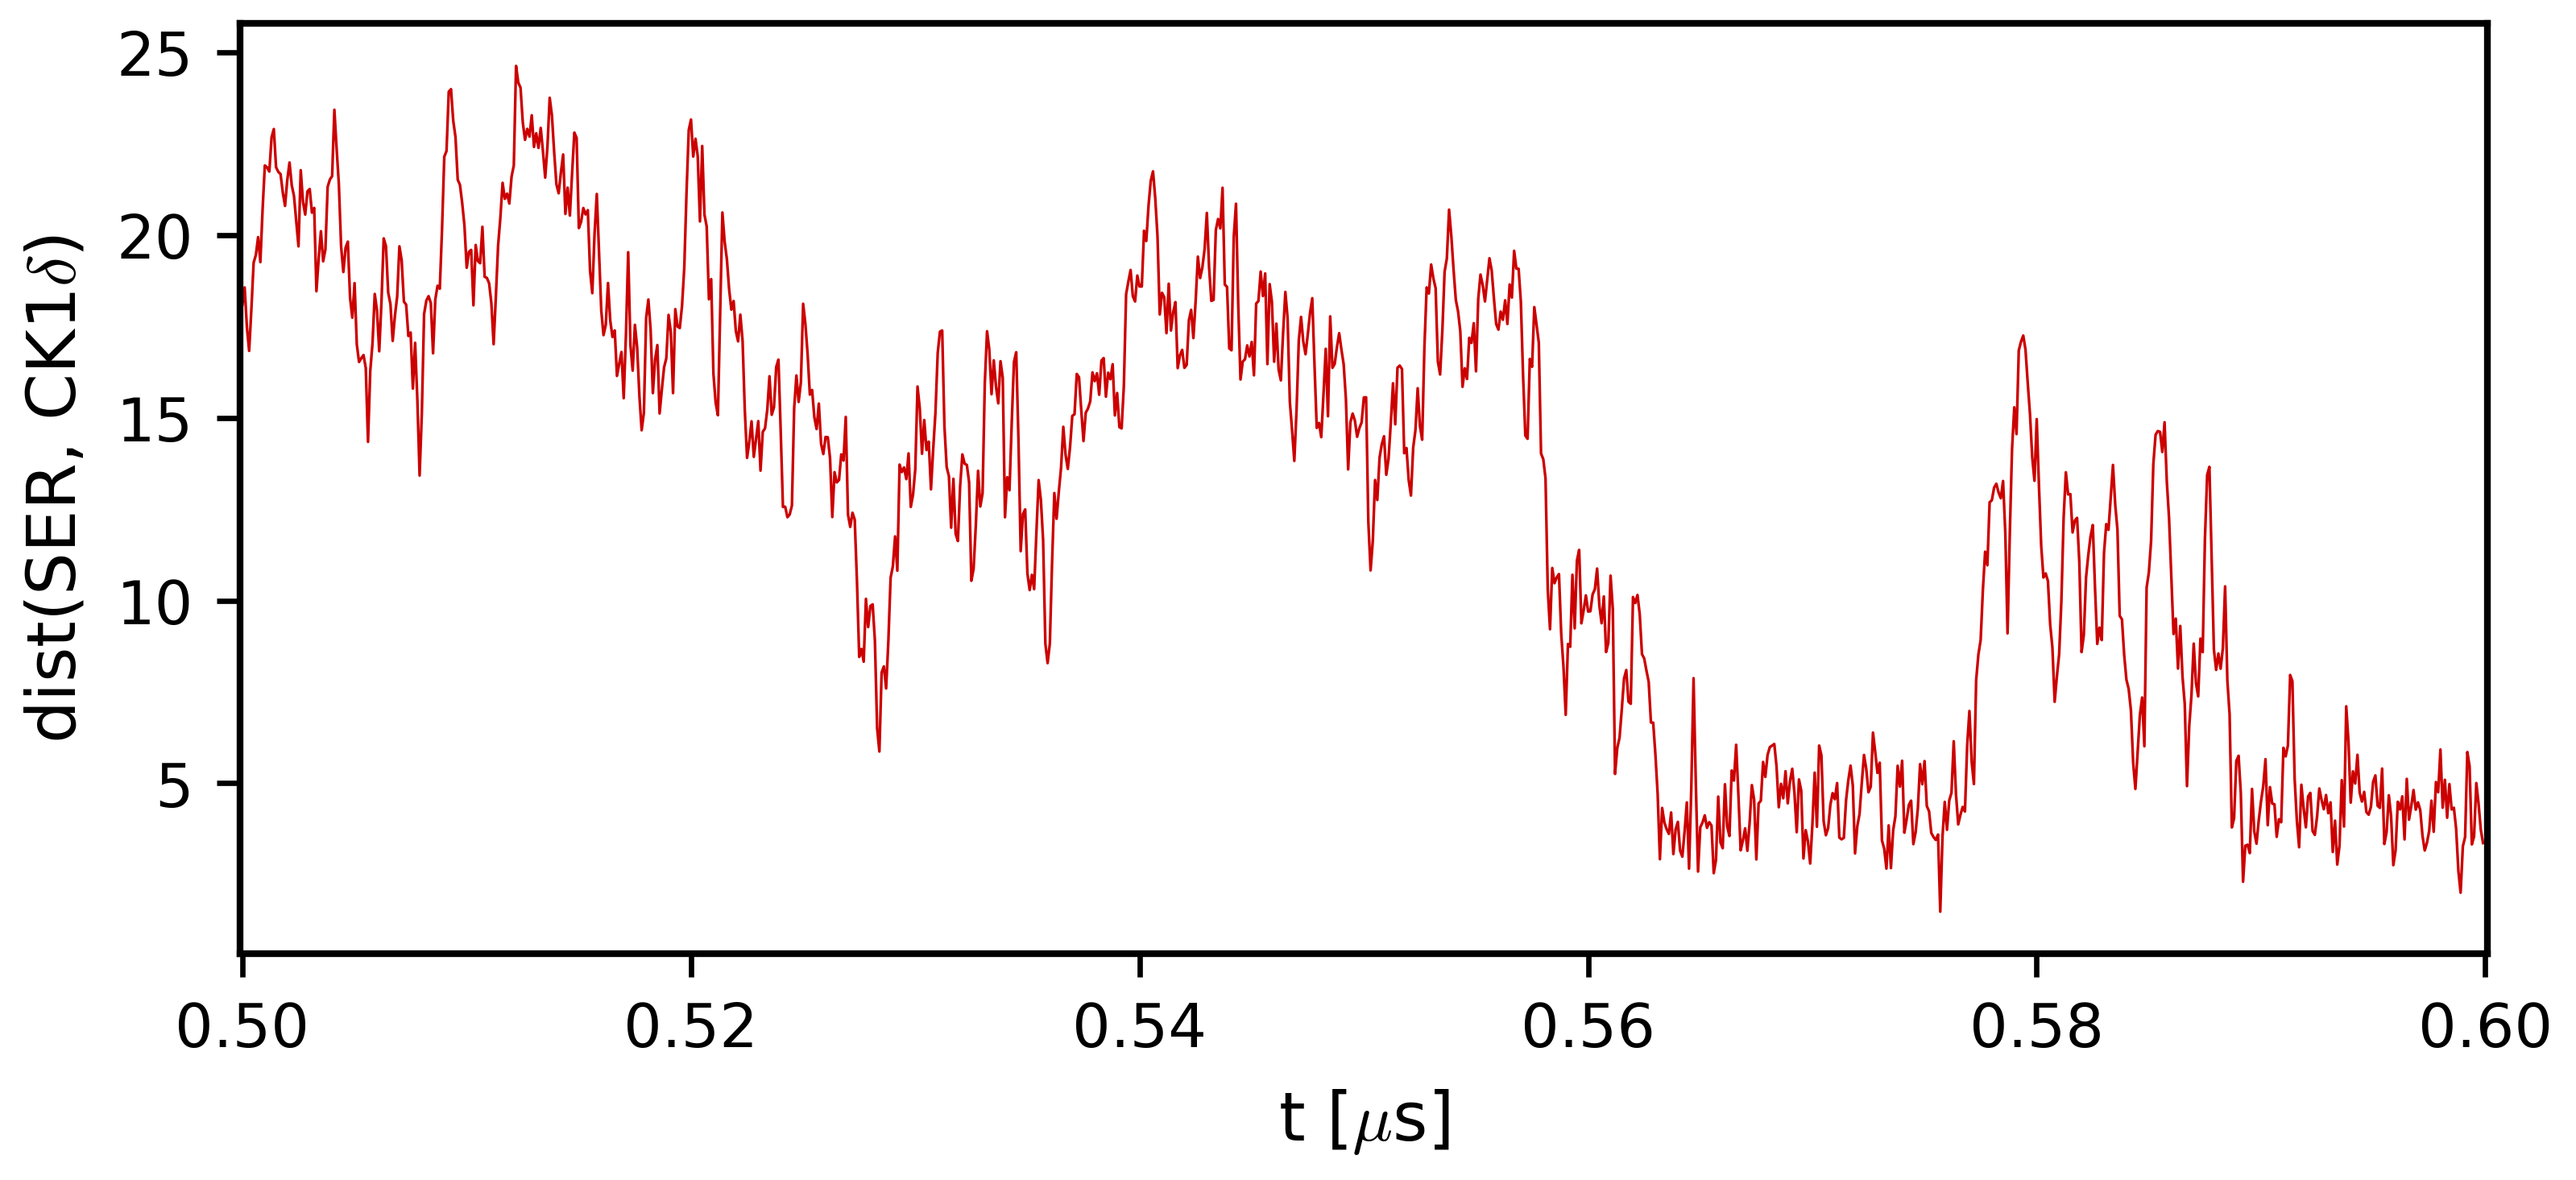

In [9]:
system = 'ck1d_pp3'   # 'pp3', 'ck1d' or 'ck1d_pp3'
dmu = '-5_+2.5'

for s in range(1, N_SIMS + 1):
    prefix = file_prefix(path_sims, system, dmu, f'sim{s}')
    d = np.concatenate([hpa.trajectory.create_distance_file(prefix + '_dump.gsd', id1=ids, id2=list(range(N_TDP)), mode='mean1')
                        for ids in SYSTEMS[system]['enz_ids']], axis=1)
    np.savetxt(prefix + '_dist.txt', d)
    hpa.plots.plot_dist(d, part_id=5, start=5000, end=6000)

## 1.2 Phosphorylation trajectories
Accepted (de)phosphorylations are read from `_changes.txt` (single enzyme) or `_contacts.txt` (CK1δ + PP3).
Rejected attempts (codes 0 and 2) are removed before building the 0/1 trajectory.

In [15]:
system = 'ck1d_pp3'
dmu = '-5_+2.5'
source = '_contacts.txt' if system == 'ck1d_pp3' else '_changes.txt'

for s in range(1, N_SIMS + 1):
    changes = np.loadtxt(file_prefix(path_sims, system, dmu, f'sim{s}') + source)
    codes, counts = np.unique(changes[:, 2], return_counts=True)
    print(f'sim{s}: event counts', dict(zip(codes, counts)))

    accepted = changes[~np.isin(changes[:, 2], (0, 2))]
    hpa.msm.changes_to_phosphostate(accepted, start_time=0, step=STEP, end_time=2_000_000_000,
                                    save=file_prefix(path_an, system, dmu, f'sim{s}') + '_phosphotraj.txt')

sim1: event counts {-1.0: 32, 0.0: 1140, 1.0: 33, 2.0: 6}


## 1.3 State trajectories
Bound: minimum distance < 3, with transition paths between 3 and 8 (`hpa.msm.boundtraj_with_dist_criterion`).
With a VAMPnet name, the bound trajectory `_boundtraj_{vampnet}.txt` produced in `VAMPnet.ipynb` is used instead.

### Single enzyme: 4 states

In [13]:
def make_states_1enzyme(system, dmu, sim, vampnet=None, min_dist=3., max_dist=8):
    prefix_an = file_prefix(path_an, system, dmu, f'sim{sim}')
    phospho = np.loadtxt(prefix_an + '_phosphotraj.txt').astype(bool)

    if vampnet is None:
        d = np.loadtxt(file_prefix(path_sims, system, dmu, f'sim{sim}') + '_dist.txt')
        bound = hpa.msm.boundtraj_with_dist_criterion(d[:, :N_TDP], min_dist=min_dist, max_dist=max_dist,
                                                      save=prefix_an + '_distboundtraj.txt')
        save = prefix_an + '_states.txt'
    else:
        bound = np.loadtxt(prefix_an + f'_boundtraj_{vampnet}.txt').astype(bool)
        save = prefix_an + f'_states_VAMPnet_{vampnet}.txt'

    return hpa.msm.create_states_trajectory(bound, phospho, save=save)


system = 'pp3'
dmu = '+2.5'
vampnet = None   # e.g. 'PP3_CAL3_tlag10'

for s in range(1, N_SIMS + 1):
    states = make_states_1enzyme(system, dmu, s, vampnet)
    print(f'sim{s}: frames per state', np.bincount(states, minlength=5)[1:])

sim1: frames per state [ 78069 247155  39996  34780]


### CK1δ + PP3: 6 states
States 7 and 8 (both enzymes bound) should never occur; if they do, they are reassigned by hand below.

In [16]:
system = 'ck1d_pp3'
dmu = '-5_+2.5'

for s in range(1, N_SIMS + 1):
    prefix_sims = file_prefix(path_sims, system, dmu, f'sim{s}')
    prefix_an = file_prefix(path_an, system, dmu, f'sim{s}')

    d = np.loadtxt(prefix_sims + '_dist.txt')
    bound_ck1d = hpa.msm.boundtraj_with_dist_criterion(d[:, :N_TDP], min_dist=3., max_dist=8,
                                                       save=prefix_an + '_distboundtraj_ck1d.txt')
    bound_pp3 = hpa.msm.boundtraj_with_dist_criterion(d[:, N_TDP:], min_dist=3., max_dist=8,
                                                      save=prefix_an + '_distboundtraj_pp3.txt')
    phospho = np.loadtxt(prefix_an + '_phosphotraj.txt').astype(bool)

    states = hpa.msm.create_states_trajectory_2enzymes(bound_ck1d, bound_pp3, phospho, save=prefix_an + '_states.txt')
    print(f'sim{s}: frames per state', np.bincount(states, minlength=9)[1:])
    if np.isin(states, (7, 8)).any():
        print(f'    WARNING: sim{s} has states 7/8 -> check and reassign them manually below')

sim1: frames per state [ 11551  98067 244089  11610   7088  27595      0      0]


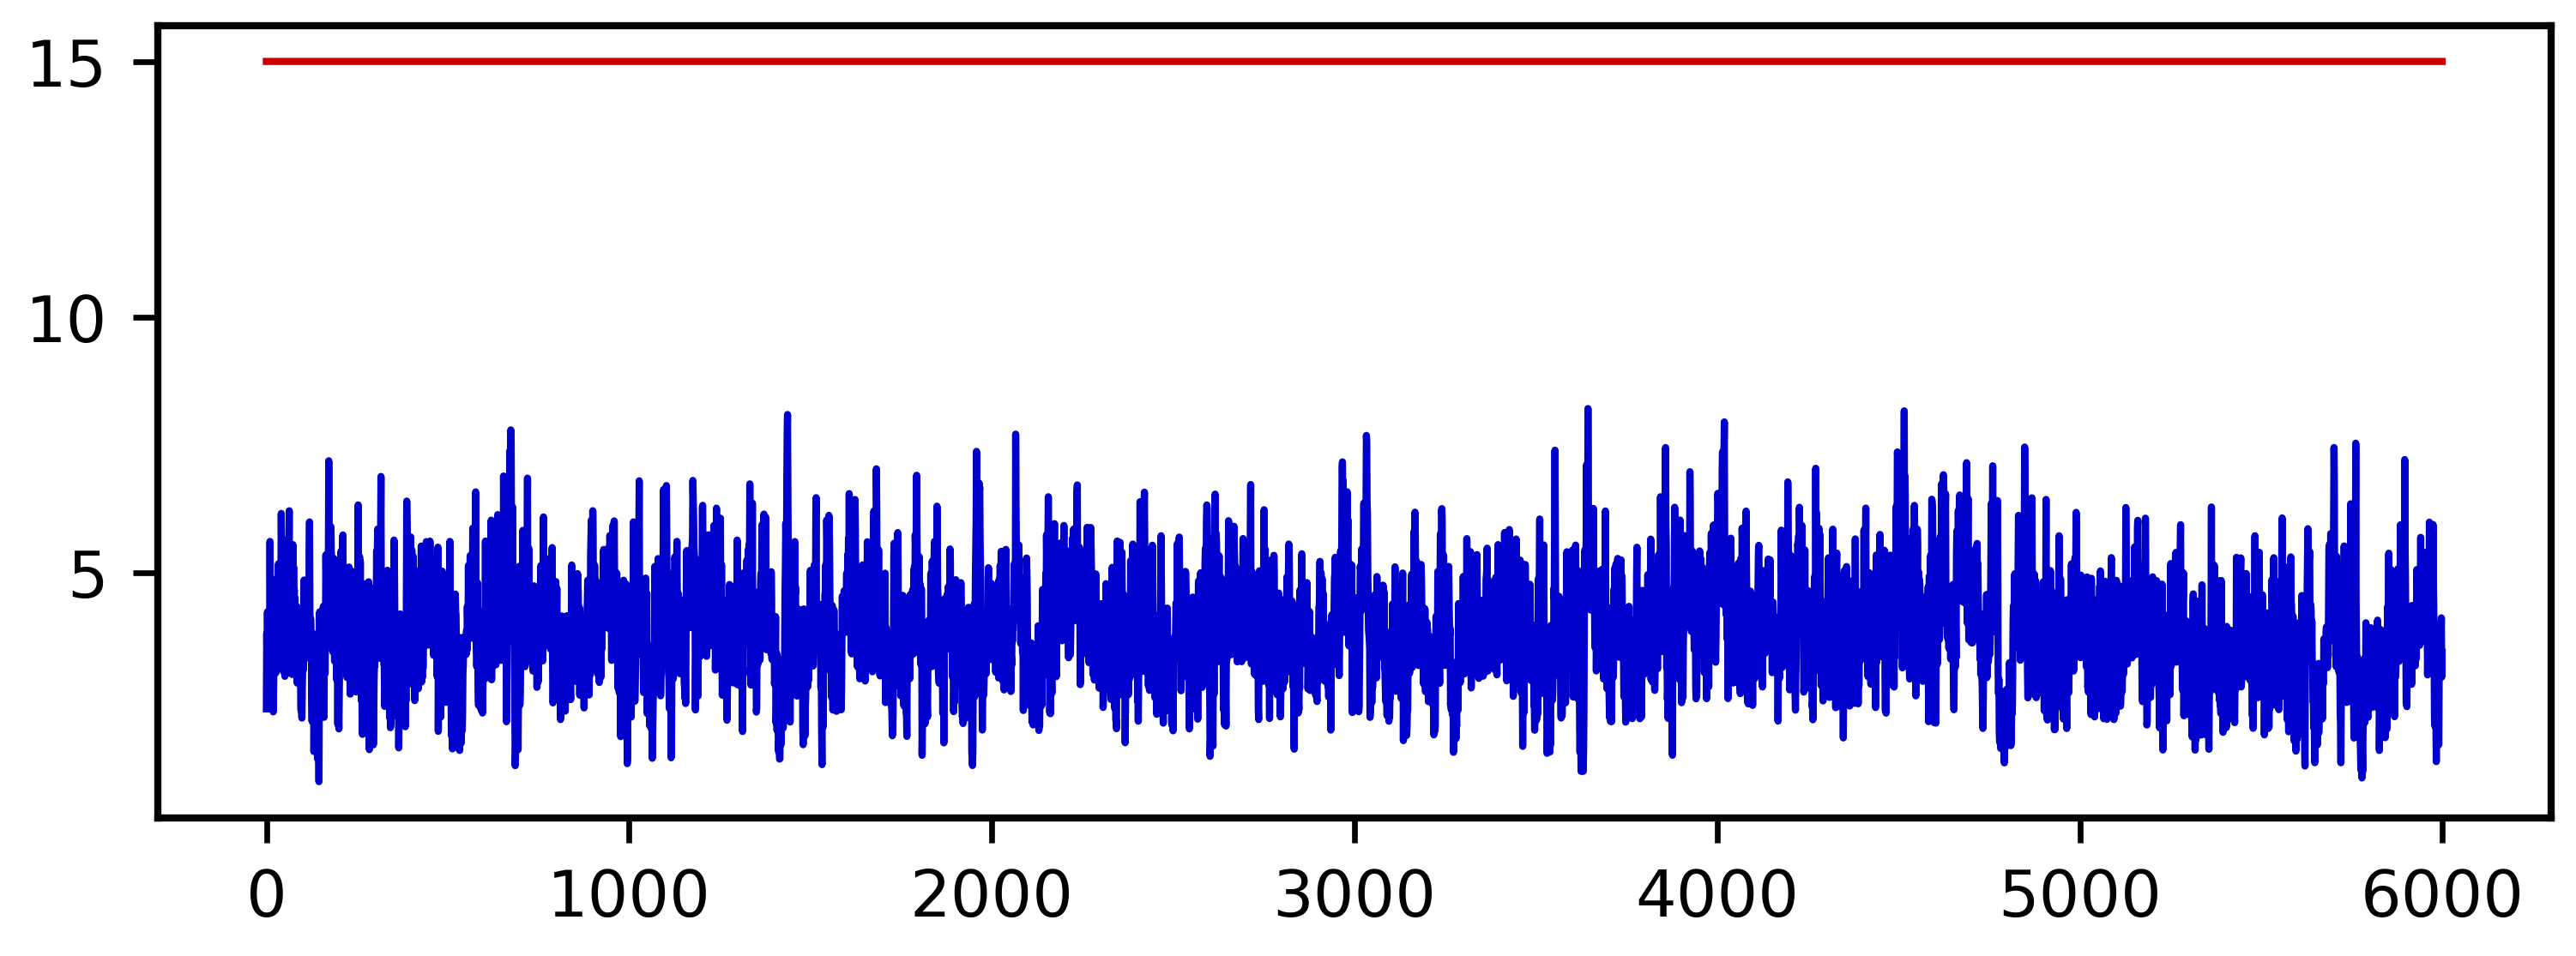

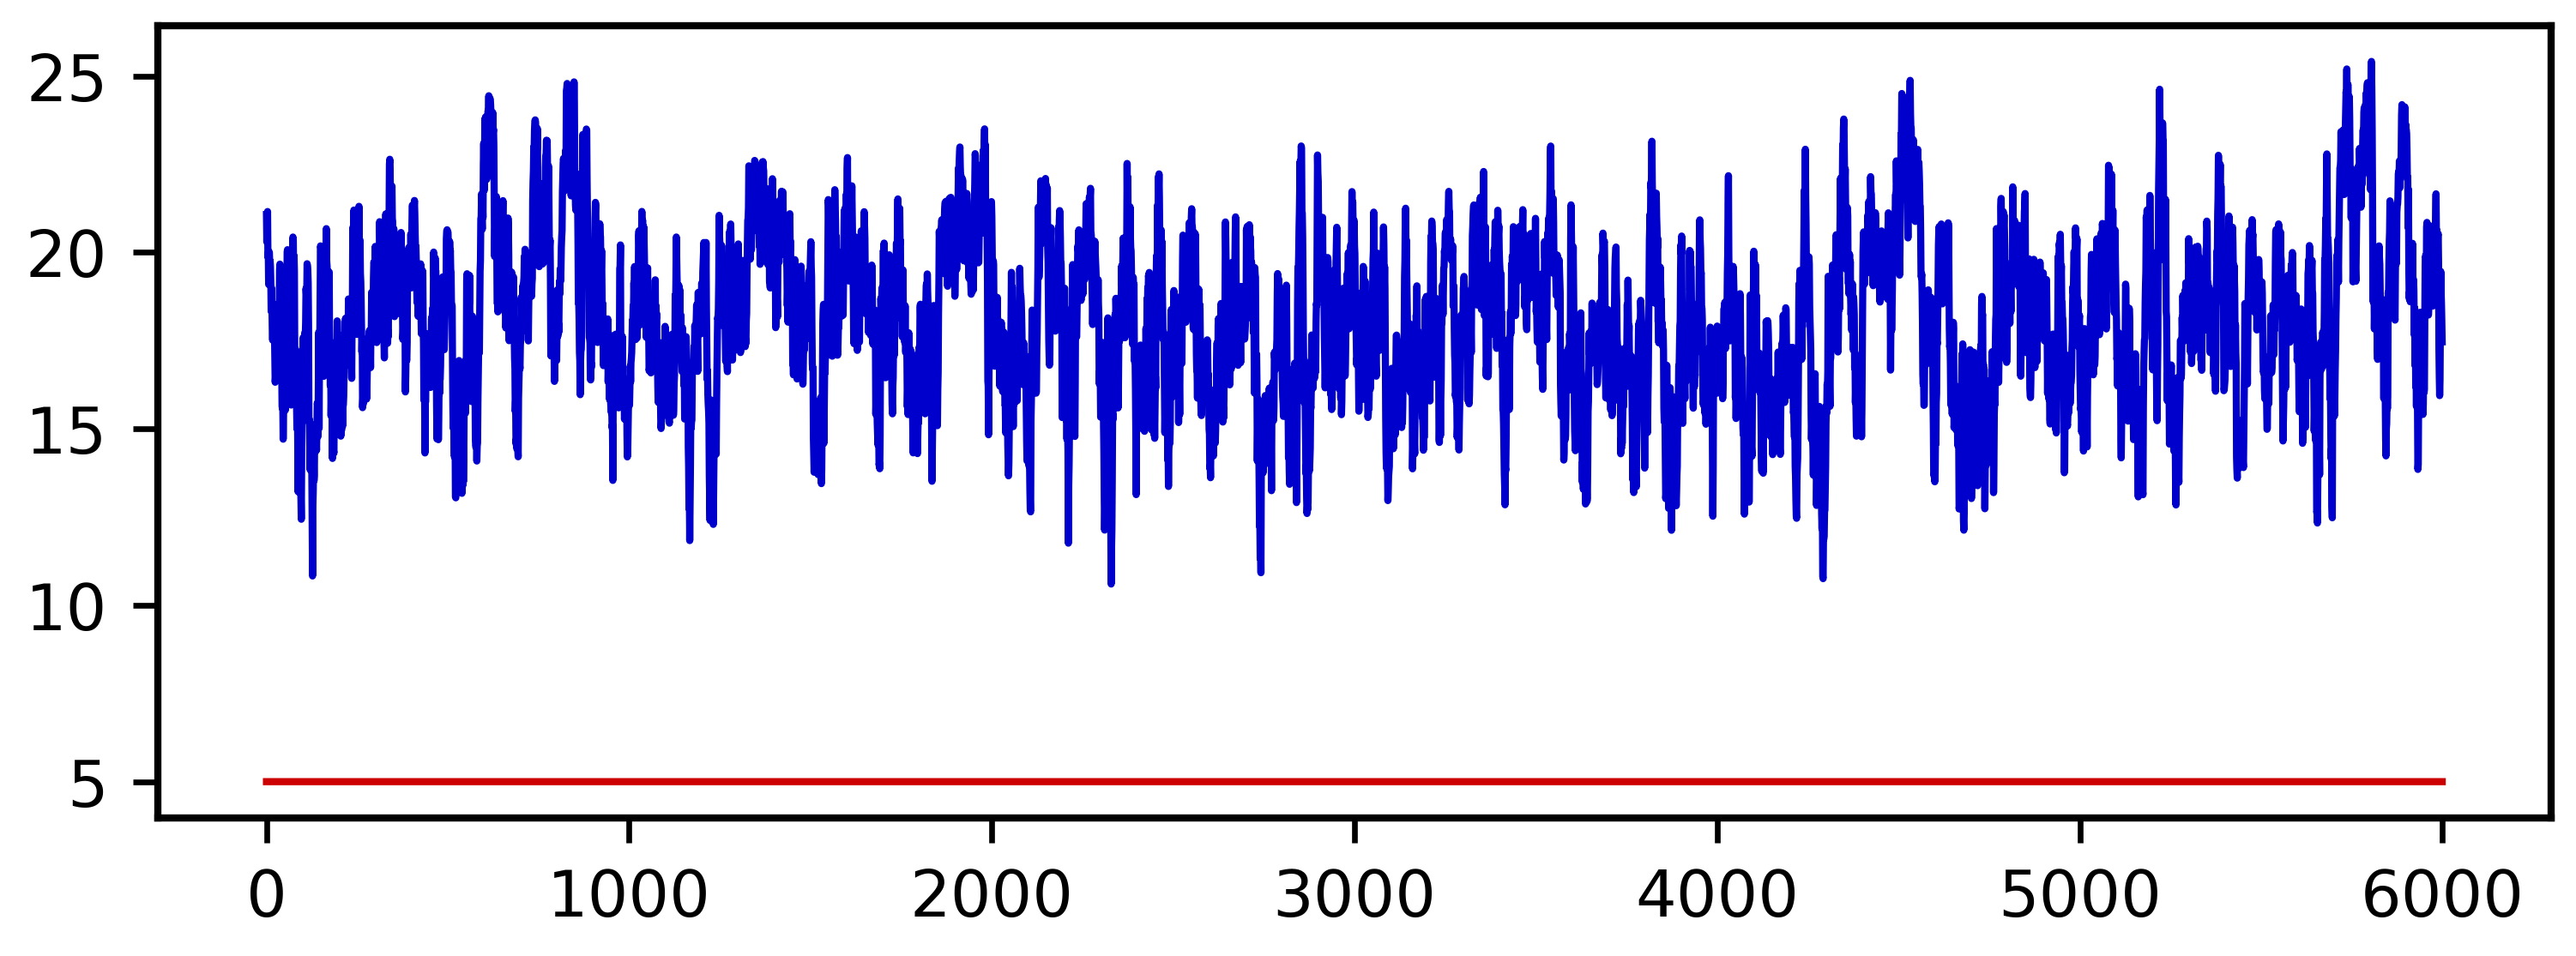

In [17]:
# visual check of the bound assignment (last simulation)
for bound, column in [(bound_ck1d, 100), (bound_pp3, 300)]:
    plt.figure(figsize=(6, 2))
    plt.plot(bound[300000:306000] * 10 + 5)
    plt.plot(d[300000:306000, column])

#### Manual check of states 7 and 8
Nothing here runs automatically: choose the simulation, inspect the frames in states 7/8,
write the reassignment by hand, then save the corrected bound and state trajectories.

In [18]:
s = 1
prefix_sims = file_prefix(path_sims, system, dmu, f'sim{s}')
prefix_an = file_prefix(path_an, system, dmu, f'sim{s}')

d = np.loadtxt(prefix_sims + '_dist.txt')
bound_ck1d = np.loadtxt(prefix_an + '_distboundtraj_ck1d.txt').astype(bool)
bound_pp3 = np.loadtxt(prefix_an + '_distboundtraj_pp3.txt').astype(bool)
phospho = np.loadtxt(prefix_an + '_phosphotraj.txt').astype(bool)
states_num = hpa.msm.create_states_trajectory_2enzymes(bound_ck1d, bound_pp3, phospho)

wrong_states = np.flatnonzero(np.isin(states_num, (7, 8)))
wrong_states

array([], dtype=int64)

In [19]:
# minimum and mean distance from CK1d and from PP3, and states before/after each wrong frame
print(np.min(d[wrong_states, :N_TDP], axis=1), np.mean(d[wrong_states, :N_TDP], axis=1))
print(np.min(d[wrong_states, N_TDP:], axis=1), np.mean(d[wrong_states, N_TDP:], axis=1))
print(states_num[wrong_states - 1], states_num[wrong_states + 1])

[] []
[] []
[] []


In [ ]:
bound_ck1d[wrong_states], bound_pp3[wrong_states]

In [ ]:
# manual reassignment: edit according to the check above before running
bound_pp3[wrong_states] = False
bound_pp3[wrong_states]

In [ ]:
# save the corrected trajectories
np.savetxt(prefix_an + '_distboundtraj_ck1d.txt', bound_ck1d)
np.savetxt(prefix_an + '_distboundtraj_pp3.txt', bound_pp3)
states_num = hpa.msm.create_states_trajectory_2enzymes(bound_ck1d, bound_pp3, phospho, save=prefix_an + '_states.txt')
print('frames per state', np.bincount(states_num, minlength=9)[1:])

# 2. Single enzyme: 4-state MSM
States: 1 U-free, 2 U-bound, 3 P-bound, 4 P-free (here 0-based: 0-3). Expected $\Delta\mu_{cycle} = -\Delta\mu_p$.

In [6]:
system = 'pp3'
dmu = '+2.5'
vampnet = ''   # '' (distance criterion) or e.g. '_VAMPnet_PP3_CAL3_tlag10'

def fig_name(label):
    return file_prefix(path_pl, system, dmu, label) + vampnet

for s, traj in enumerate(load_state_list(system, dmu, vampnet), start=1):
    print(f'sim{s}: dmu = {hpa.msm.dmu_with_error(traj, 60, kT, pow_bin=10, n_resample=10)}')

states = load_states(system, dmu, vampnet)
print(len(states), 'frames, states', np.unique(states))

sim1: dmu = (-2.198587424774444, 0.42174405882068455)
sim2: dmu = (-2.0717128950413692, 0.4854647542933304)
sim3: dmu = (-2.920346013299146, 0.647810991920287)
sim4: dmu = (-1.9844774493937083, 0.36707097356965984)
sim5: dmu = (-2.528538156753628, 0.46379474667434517)
1990378 frames, states [0 1 2 3]


## Implied timescales

100%|█████████████████████████████████████████████████████████████████████| 7/7 [00:00<00:00,  8.69it/s]
/localscratch/zippoema/lib/python_envs/hpa_env/lib/python3.11/site-packages/deeptime/markov/tools/analysis/_decomposition.py:496: ImaginaryEigenValueWarning: Using eigenvalues with non-zero imaginary part
  warnings.warn('Using eigenvalues with non-zero imaginary part', ImaginaryEigenValueWarning)


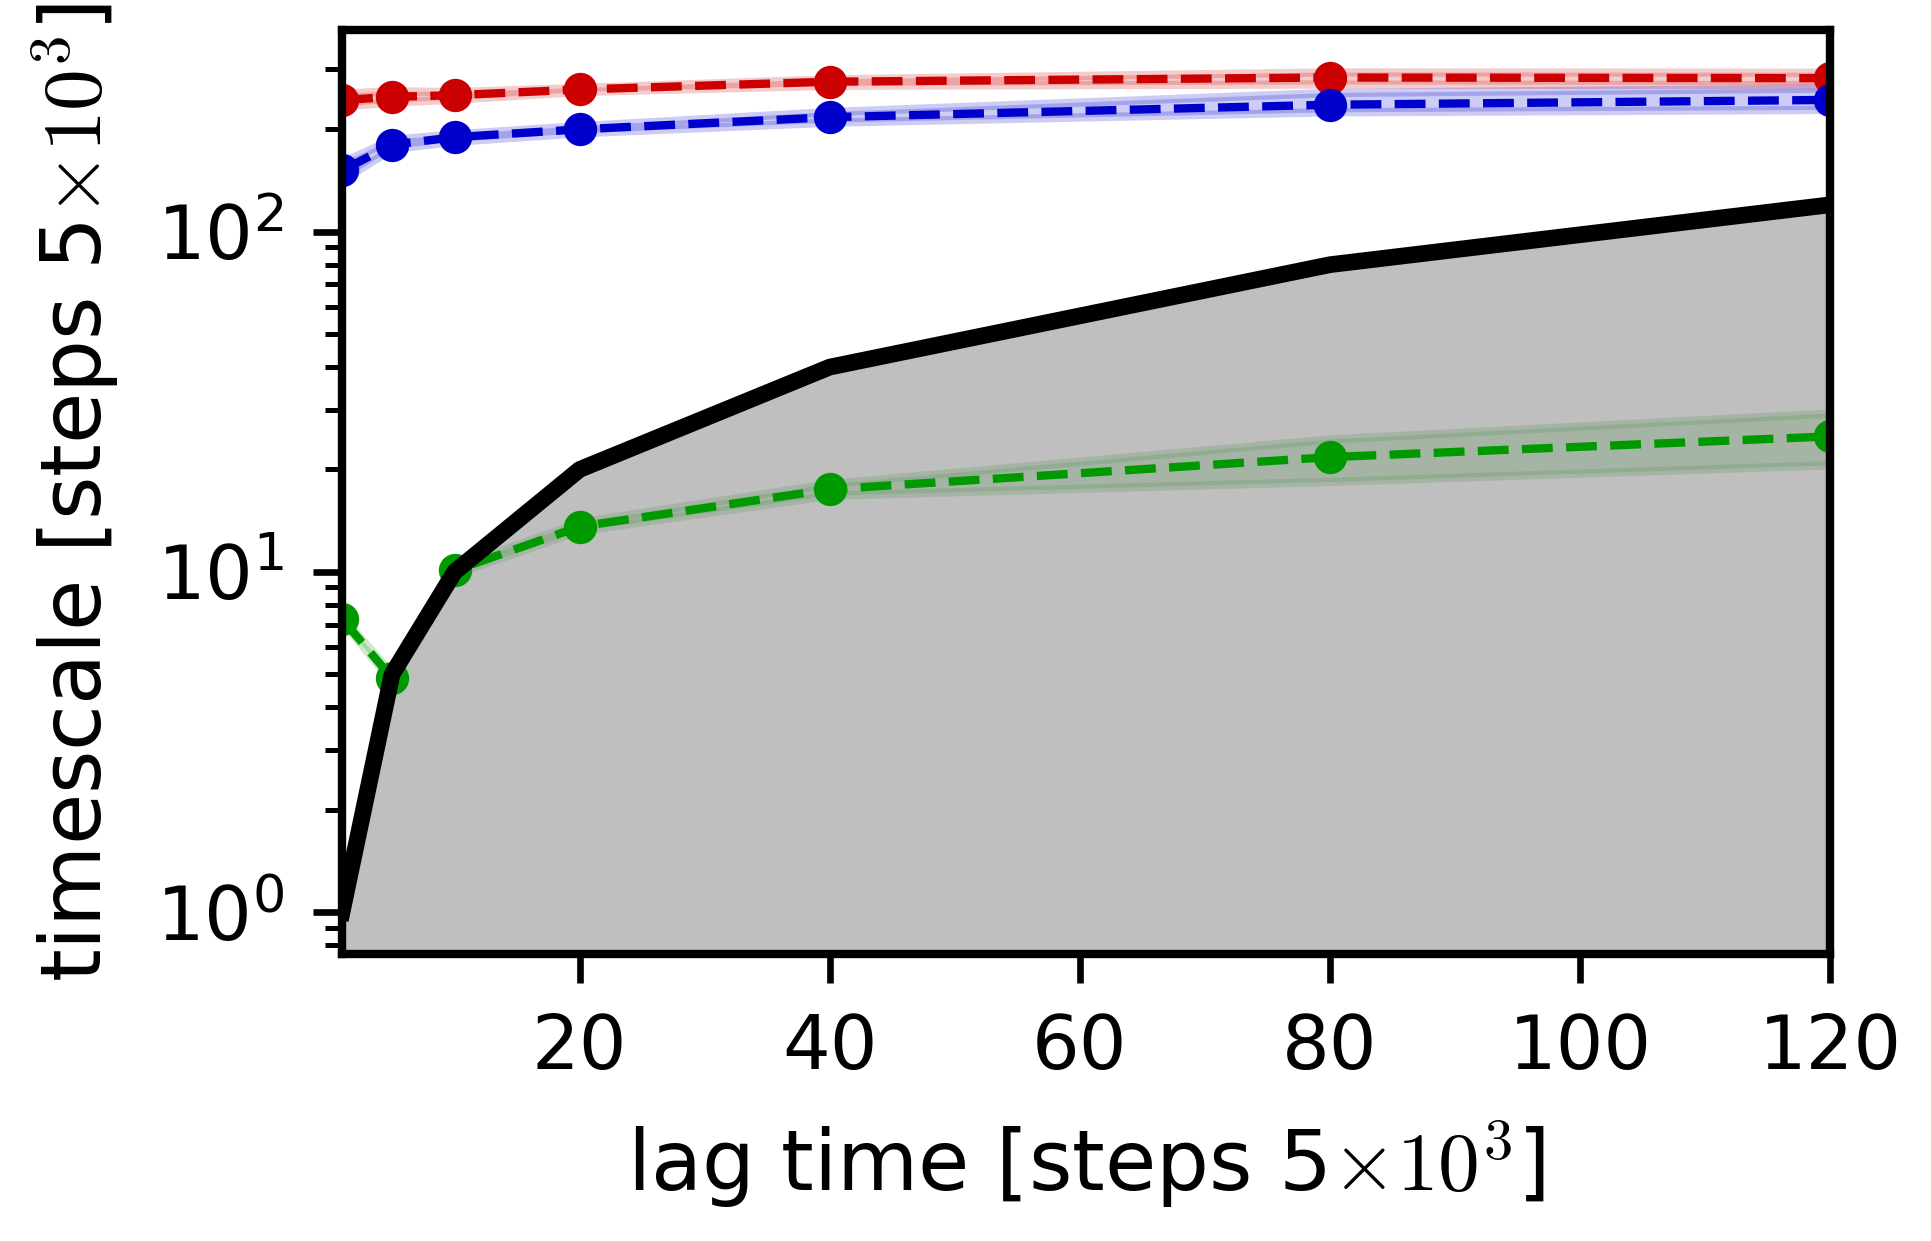

In [28]:
lagtimes = np.array([1, 5, 10, 20, 40, 80, 120])
models = bayesian_msms(states, lagtimes, n_steps=2**12)
plot_its(models, xlim=(lagtimes[0], lagtimes[-1]), save=fig_name('its'))

## Chapman-Kolmogorov test
Predictions from the lag-1 model.

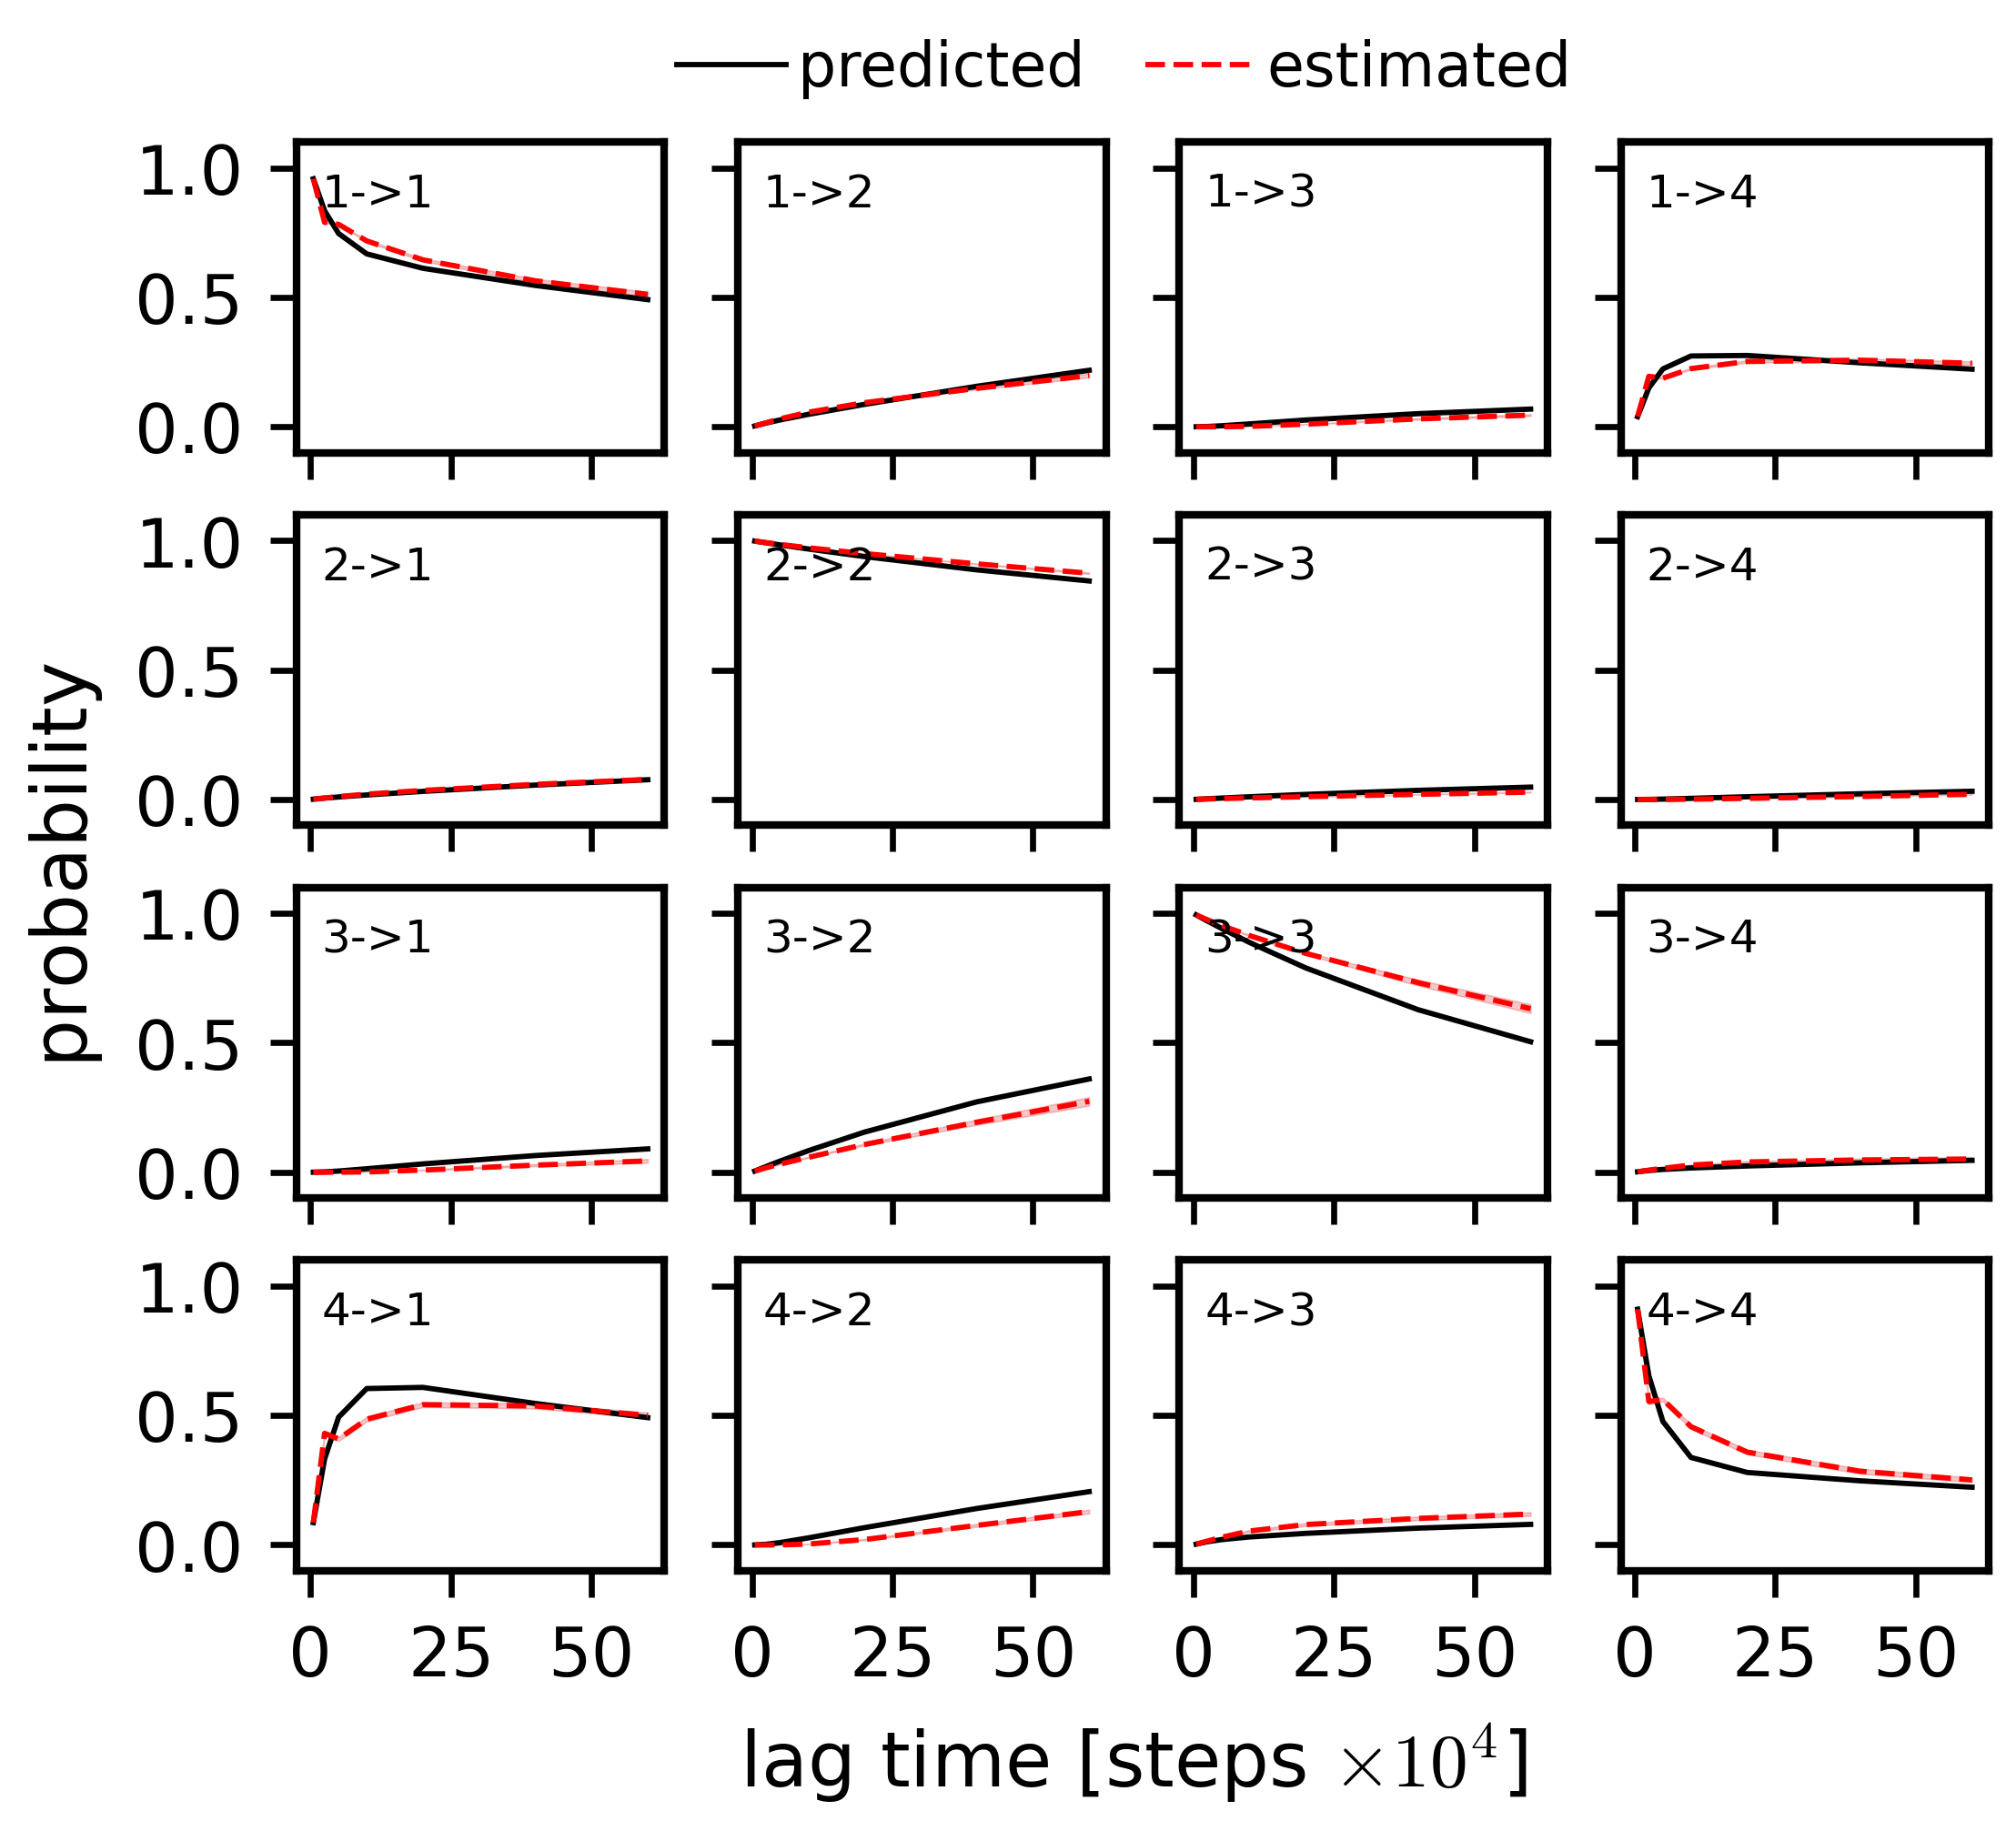

In [29]:
pred_ck, est_ck, est_err_ck = hpa.msm.ck_test(states, lagtimes)
plot_ck_grid(lagtimes * RDUMP / 10, pred_ck, est_ck, est_err_ck, figsize=(4, 3.4),
             xticks=list(np.round(np.array([0, 50, 100]) * RDUMP / 10).astype(int)), legend_loc=(1., 3.5),
             save=fig_name('ck-test'))

## $\Delta\mu$ vs lag time

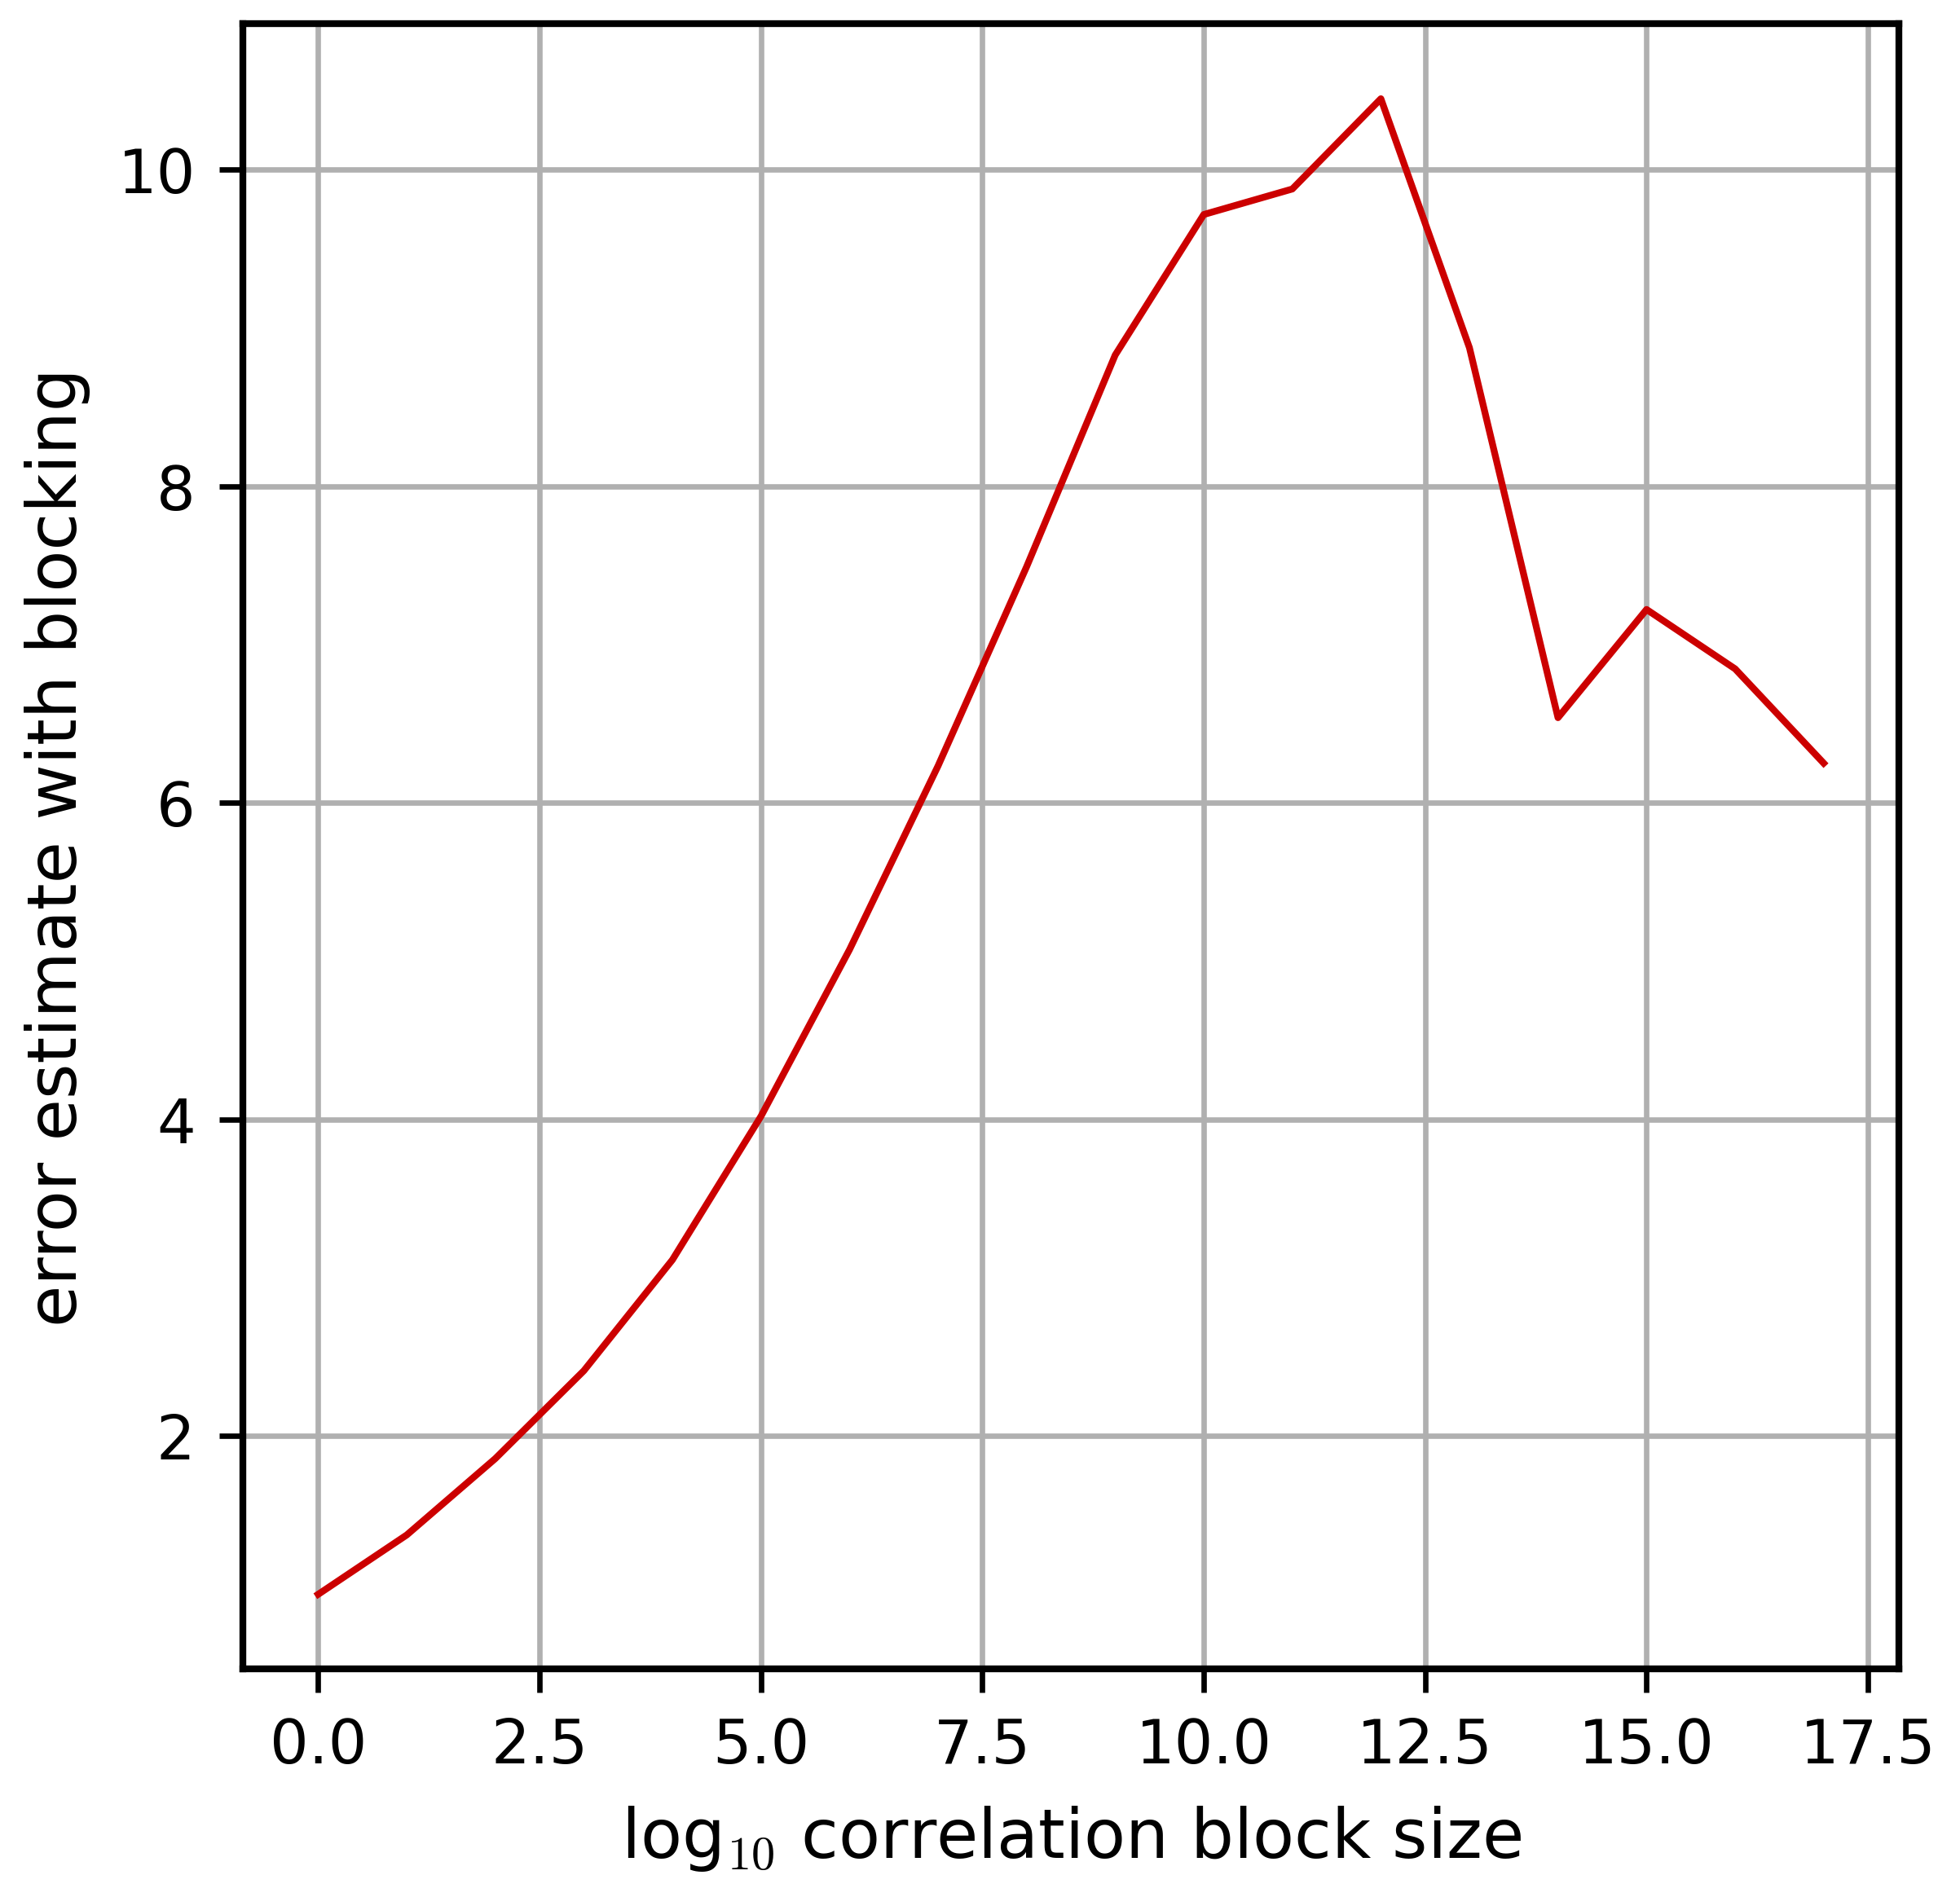

In [30]:
hpa.stats.autocorr_bin(states, 18, 1000)

100%|█████████████████████████████████████████████████████████████████████| 9/9 [00:15<00:00,  1.77s/it]


array([[-1.8564328 ,  0.44163281],
       [-1.91328378,  0.39014682],
       [-2.01198038,  0.44065788],
       [-2.09361925,  0.37133703],
       [-2.13719491,  0.37512389],
       [-2.20290542,  0.46770322],
       [-2.24467648,  0.45493438],
       [-2.33643115,  0.46340041],
       [-2.3619319 ,  0.48009473]])

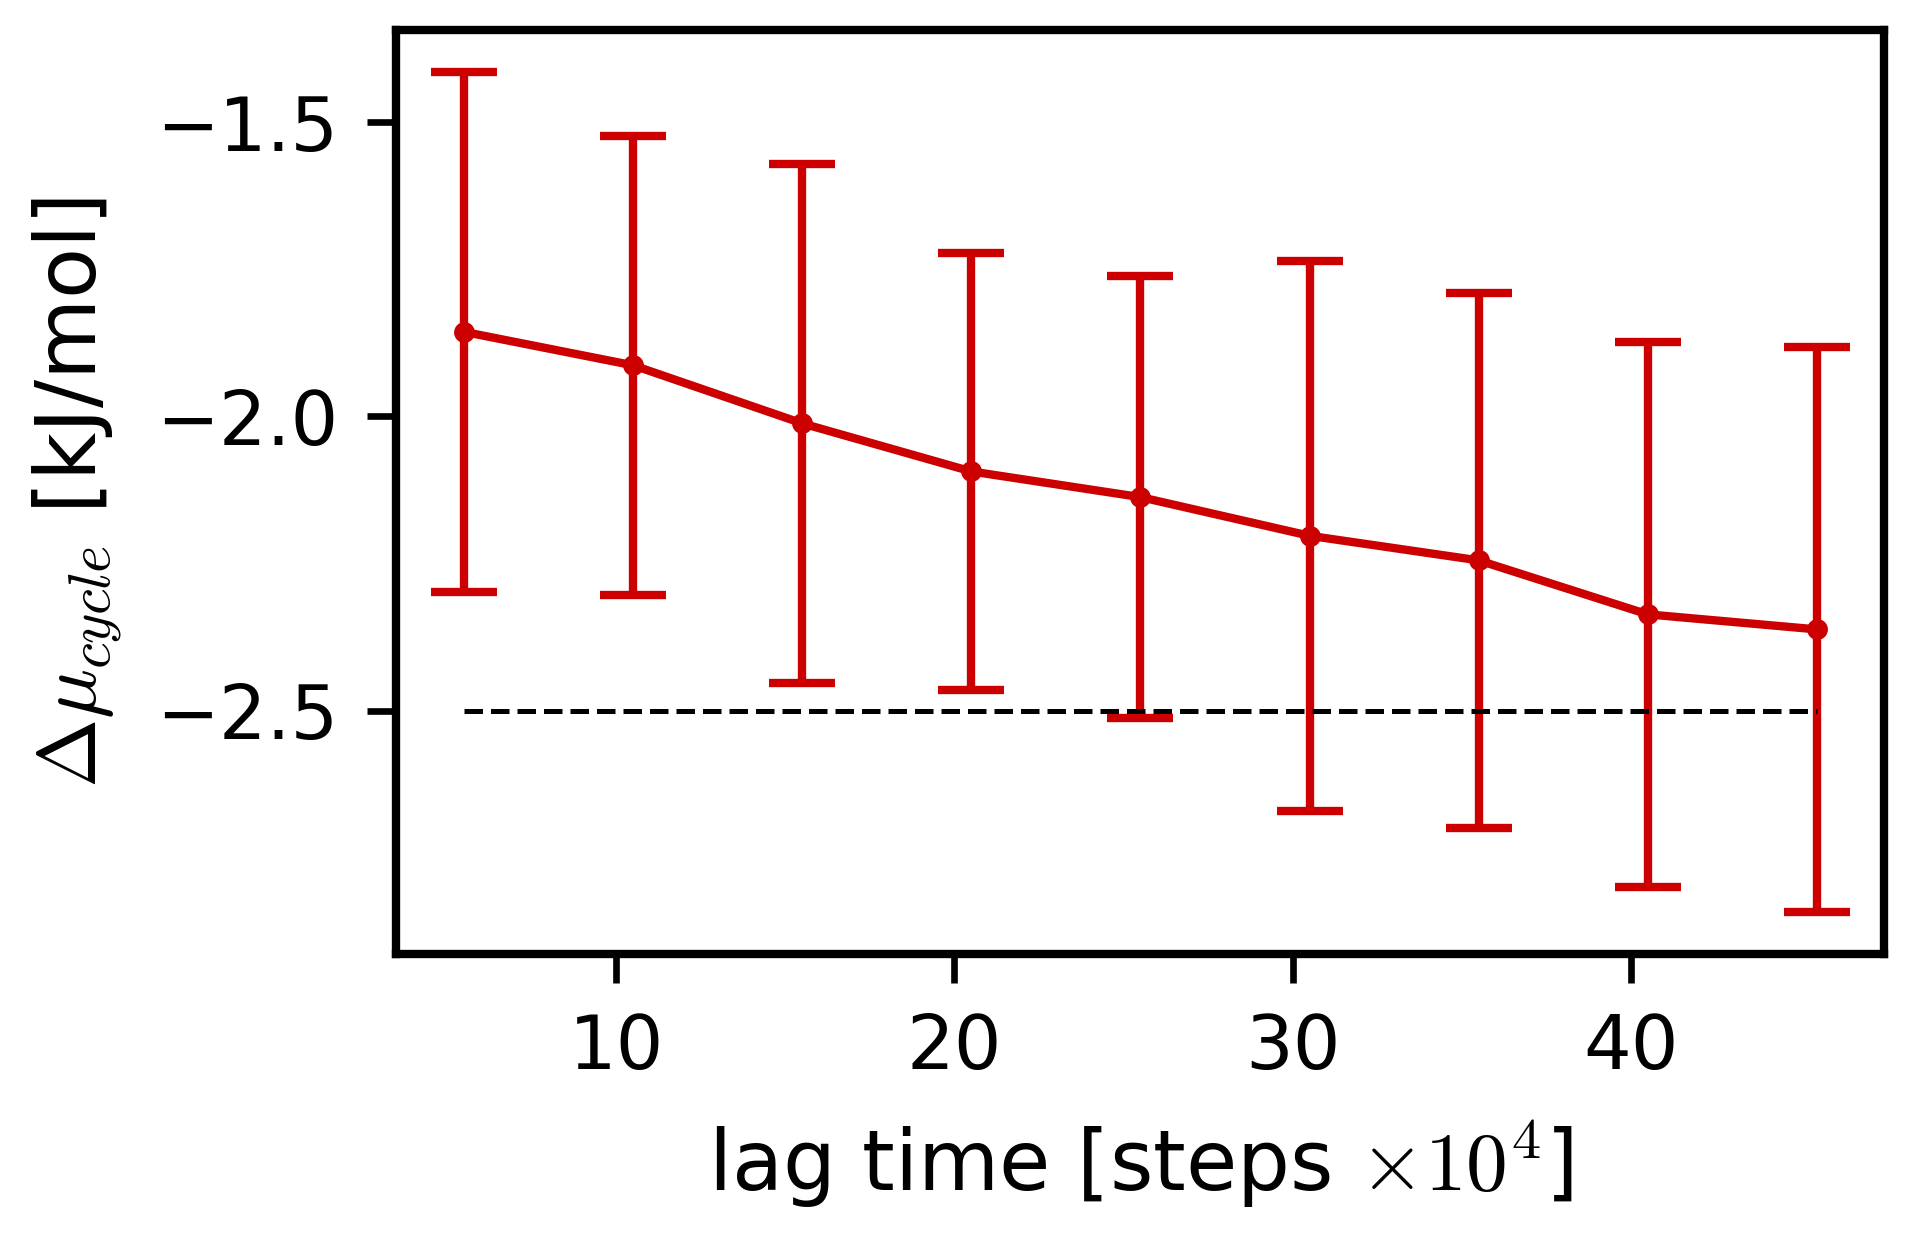

In [31]:
lags_dmu = np.arange(11, 101, 10)
dmus = np.array([hpa.msm.dmu_with_error(states, lag, kT, pow_bin=10, n_resample=20) for lag in tqdm(lags_dmu)])
plot_dmu_vs_lag(lags_dmu, dmus, -float(dmu), save=fig_name('dmu'))
dmus

## Transition network at lag 70

array([[0.580179  , 0.13686773, 0.02561956, 0.25733371],
       [0.05315434, 0.92003053, 0.017337  , 0.00947813],
       [0.02142518, 0.17328762, 0.75810973, 0.04717747],
       [0.54067232, 0.05899928, 0.09799879, 0.30232961]])

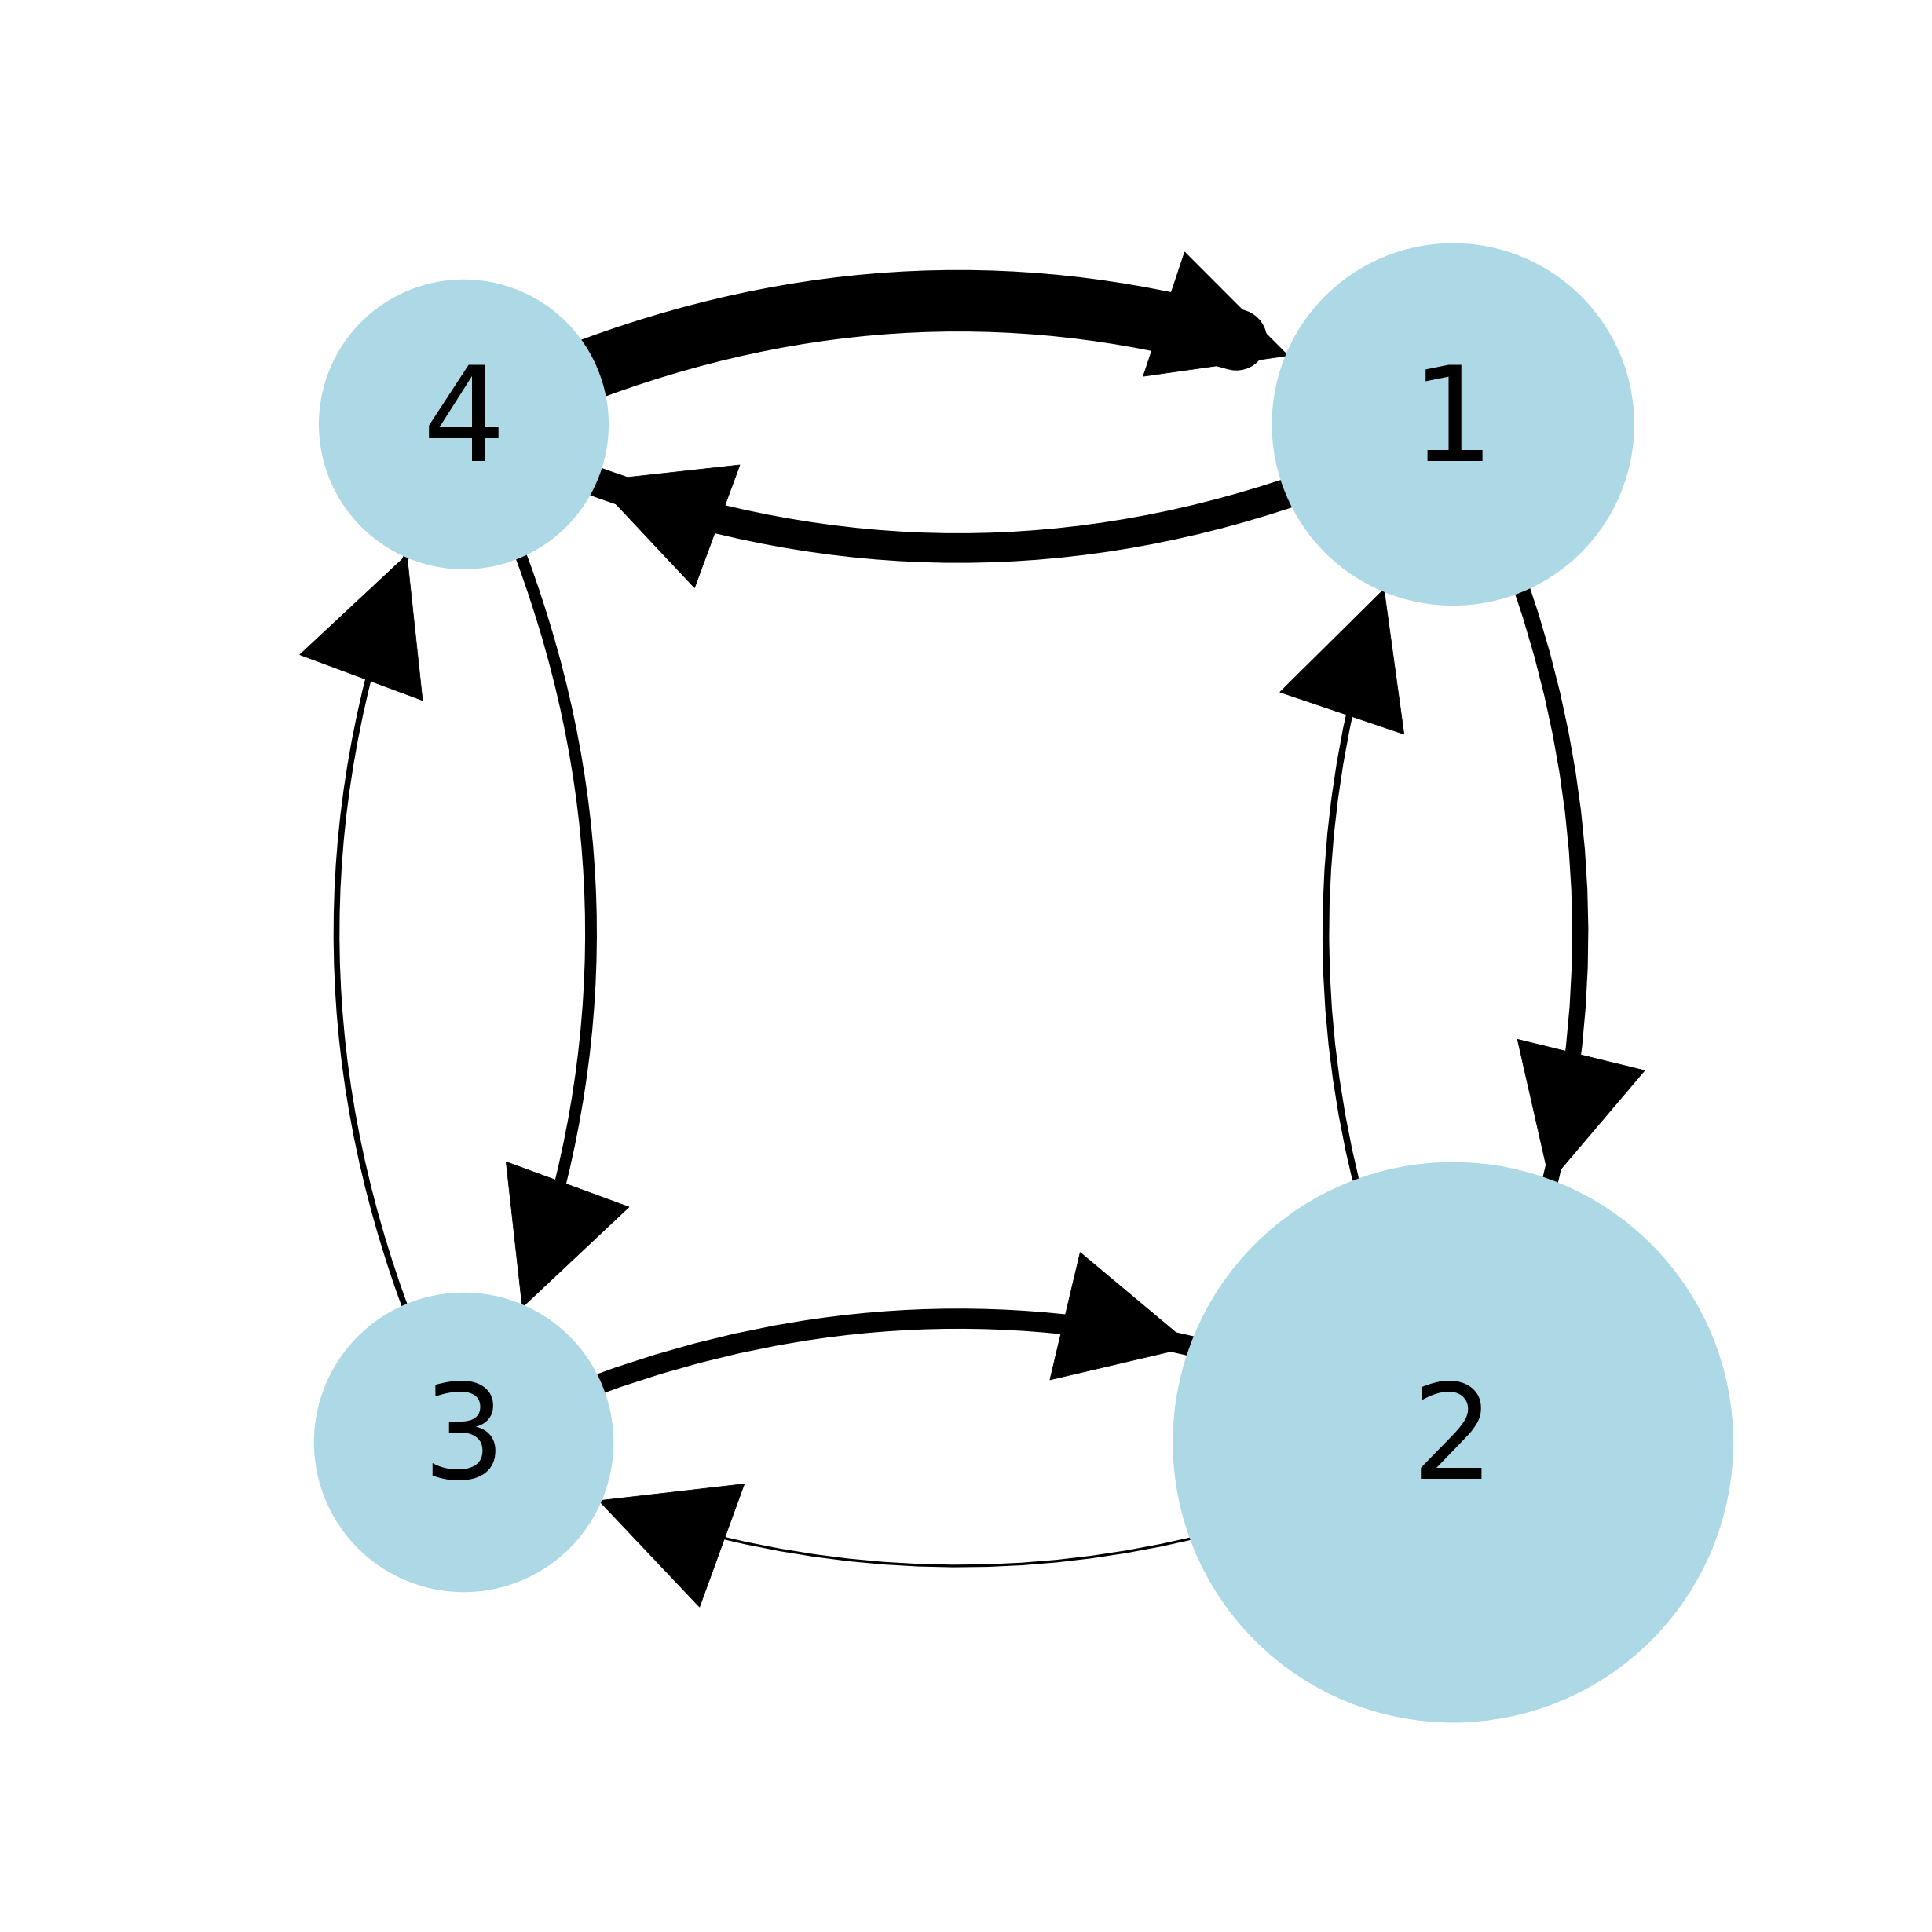

In [69]:
counts = markov.TransitionCountEstimator(lagtime=70, count_mode='effective').fit_fetch(states)
msm = markov.msm.BayesianMSM(n_samples=10000, n_steps=2**8, reversible=False).fit_fetch(counts)
tr_mat = msm.gather_stats('transition_matrix').mean
st_distr = msm.gather_stats('stationary_distribution').mean

plot_cycle_4states(tr_mat, st_distr, save=fig_name('cycle_round'))
tr_mat

## Dependence on $\Delta\mu_p$
Edge contributions $k_BT\ln(T_{ij}/T_{ji})$ and total $\Delta\mu_{cycle}$ at lag 70 for every simulated $\Delta\mu_p$.

In [33]:
system = 'pp3'   # 'pp3' or 'ck1d'
lag = 70
dmus_sim = SYSTEMS[system]['dmus']
dmus_arr = -np.array(dmus_sim, dtype=float)

states_list = [load_states(system, d) for d in tqdm(dmus_sim)]


100%|█████████████████████████████████████████████████████████████████████| 4/4 [00:00<00:00, 27.80it/s]


In [34]:
edges = [hpa.msm.edge_dmus_bootstrap(st, lag, kT, pow_bin=11, n_resample=15) for st in tqdm(states_list)]
edge_dmu = np.array([e for e, _ in edges])
edge_err = np.array([err for _, err in edges])


100%|█████████████████████████████████████████████████████████████████████| 4/4 [00:33<00:00,  8.27s/it]


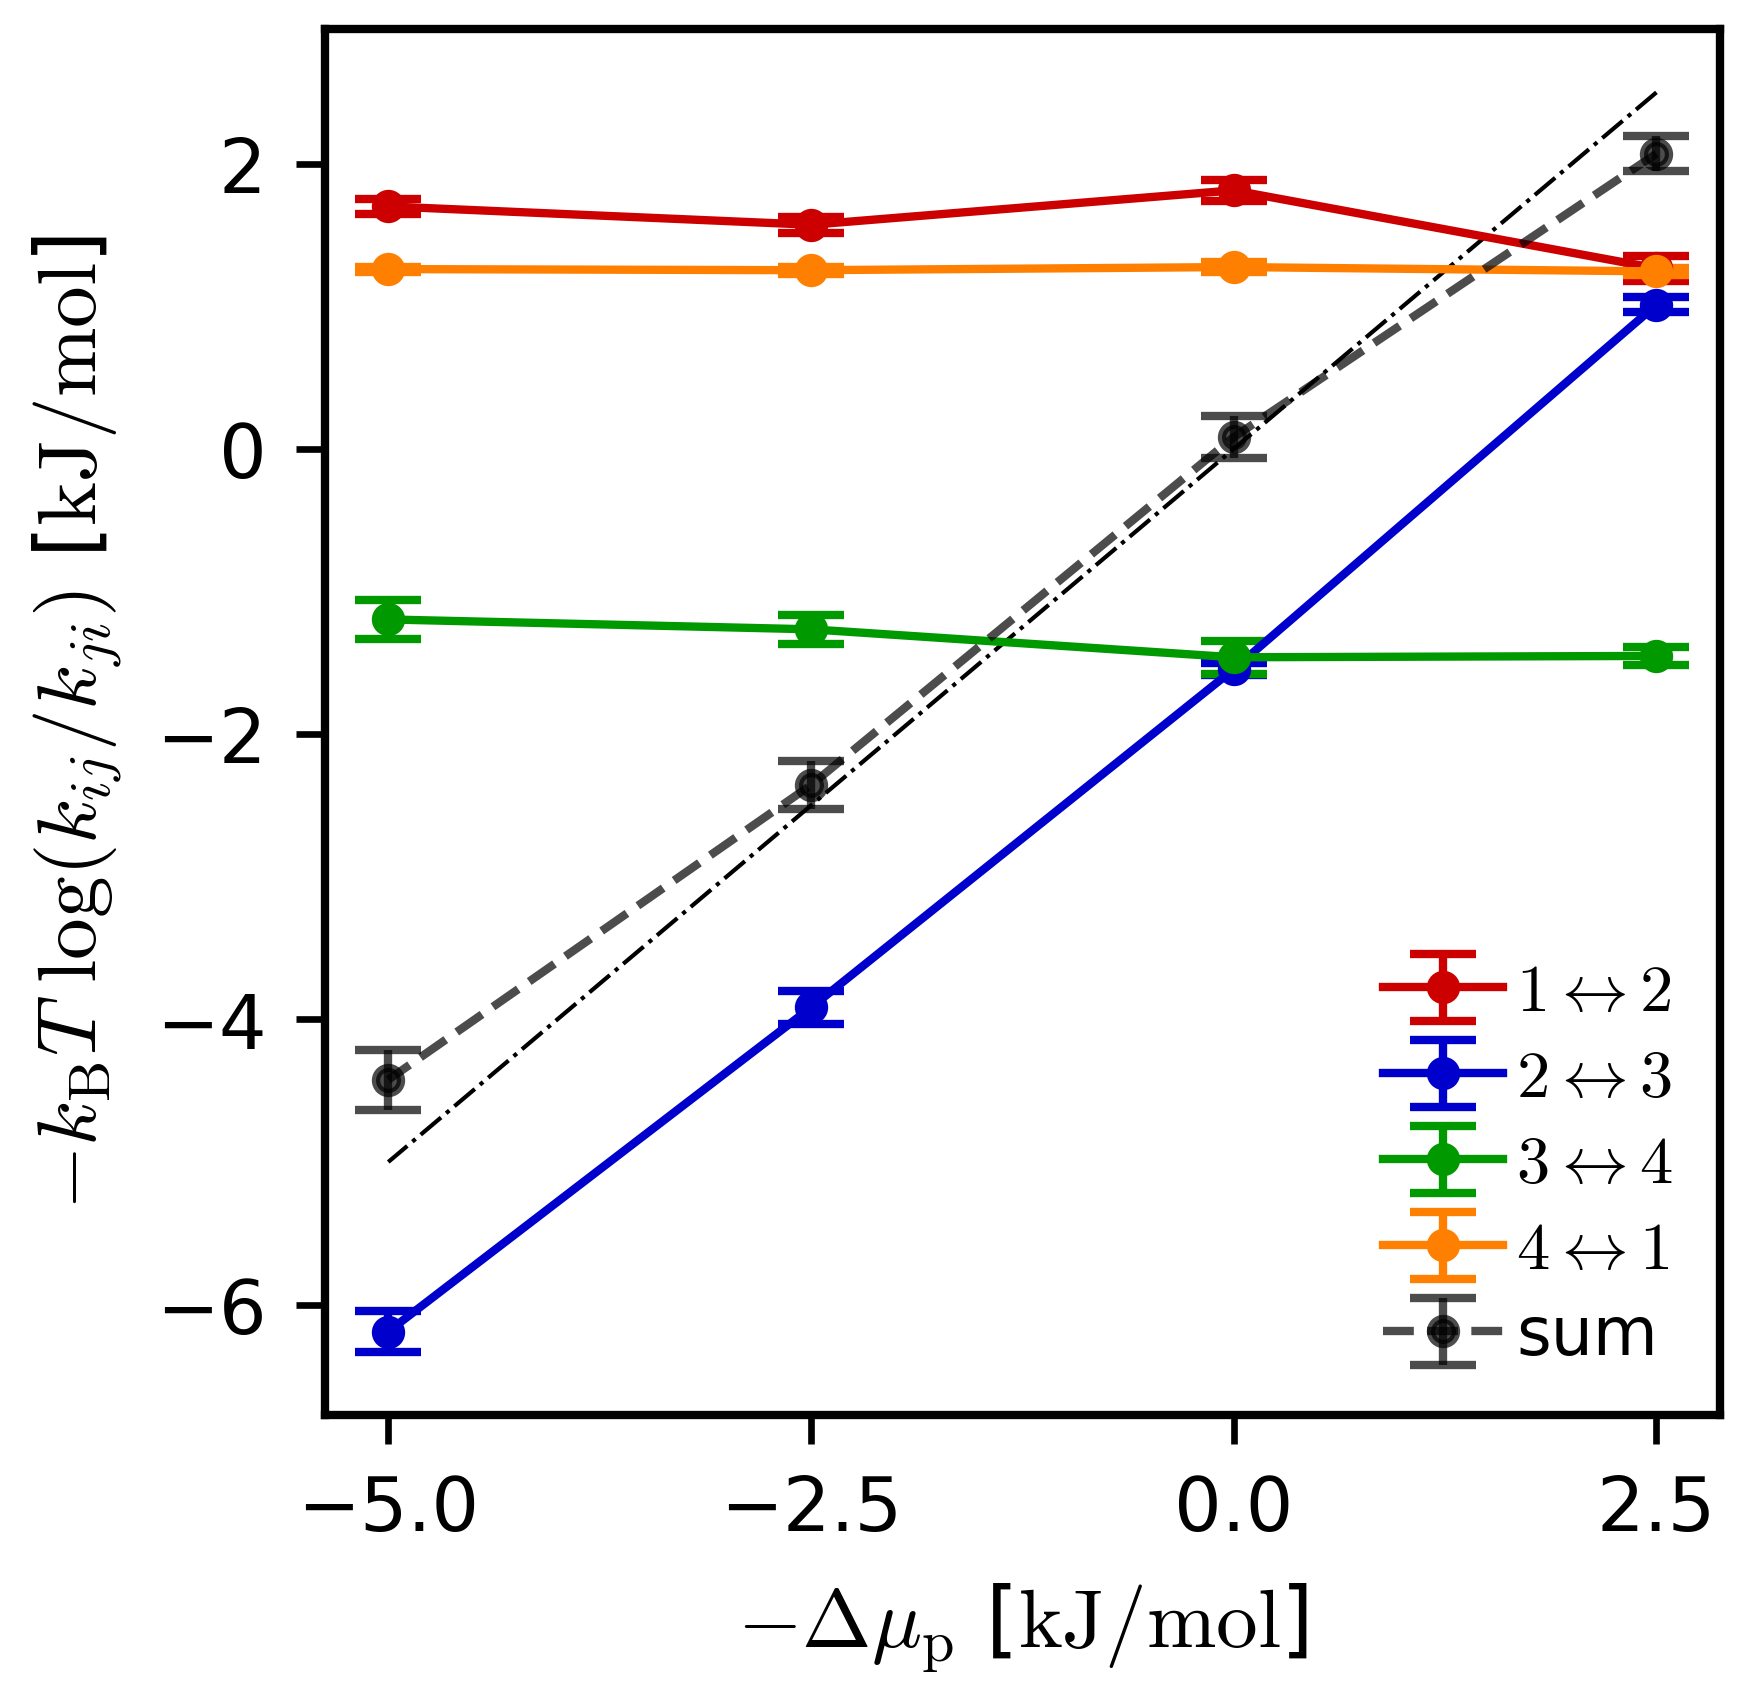

In [35]:
plt.figure(figsize=(3, 3))
for k in range(4):
    plt.errorbar(dmus_arr, edge_dmu[:, k], edge_err[:, k], capsize=4, fmt='o-',
                 label=rf'${k+1} \leftrightarrow {(k+1) % 4 + 1}$')
plt.errorbar(dmus_arr, edge_dmu.sum(axis=1), np.sqrt(np.sum(edge_err**2, axis=1)),
             capsize=4, fmt='o--k', alpha=0.7, label='sum')
plt.plot(dmus_arr, dmus_arr, '-.k', lw=0.5)
plt.xlabel(r'$ -\Delta \mu_\mathrm{p}$ [$\mathrm{kJ/mol}$]')
plt.ylabel(r'$- k_\mathrm{B } T~ \log(k_{ij}/k_{ji})$ [$\mathrm{kJ/mol}$]')
plt.legend(ncols=1)
plt.xticks(dmus_arr)
savefig(summary_prefix(system, 'dmu_contributions'))

### Final $\Delta\mu_{cycle}$ (distance criterion and VAMPnet)

In [36]:
dmu_results = np.array([hpa.msm.dmu_with_error(st, lag, kT, pow_bin=12, n_resample=15) for st in tqdm(states_list)])

popt, pcov = curve_fit(linear, dmus_arr, dmu_results[:, 0])
print('slope, intercept:', popt, '+-', np.sqrt(pcov.diagonal()))
dmu_results


100%|█████████████████████████████████████████████████████████████████████| 4/4 [00:32<00:00,  8.19s/it]

slope, intercept: [ 0.87681823 -0.0607572 ] +- [0.0238764  0.07310626]


array([[ 2.07030696,  0.12321872],
       [ 0.08277994,  0.15290013],
       [-2.35693279,  0.2169601 ],
       [-4.42327403,  0.31290275]])

VAMPnet: -2.221871015493095 0.2097291409356573


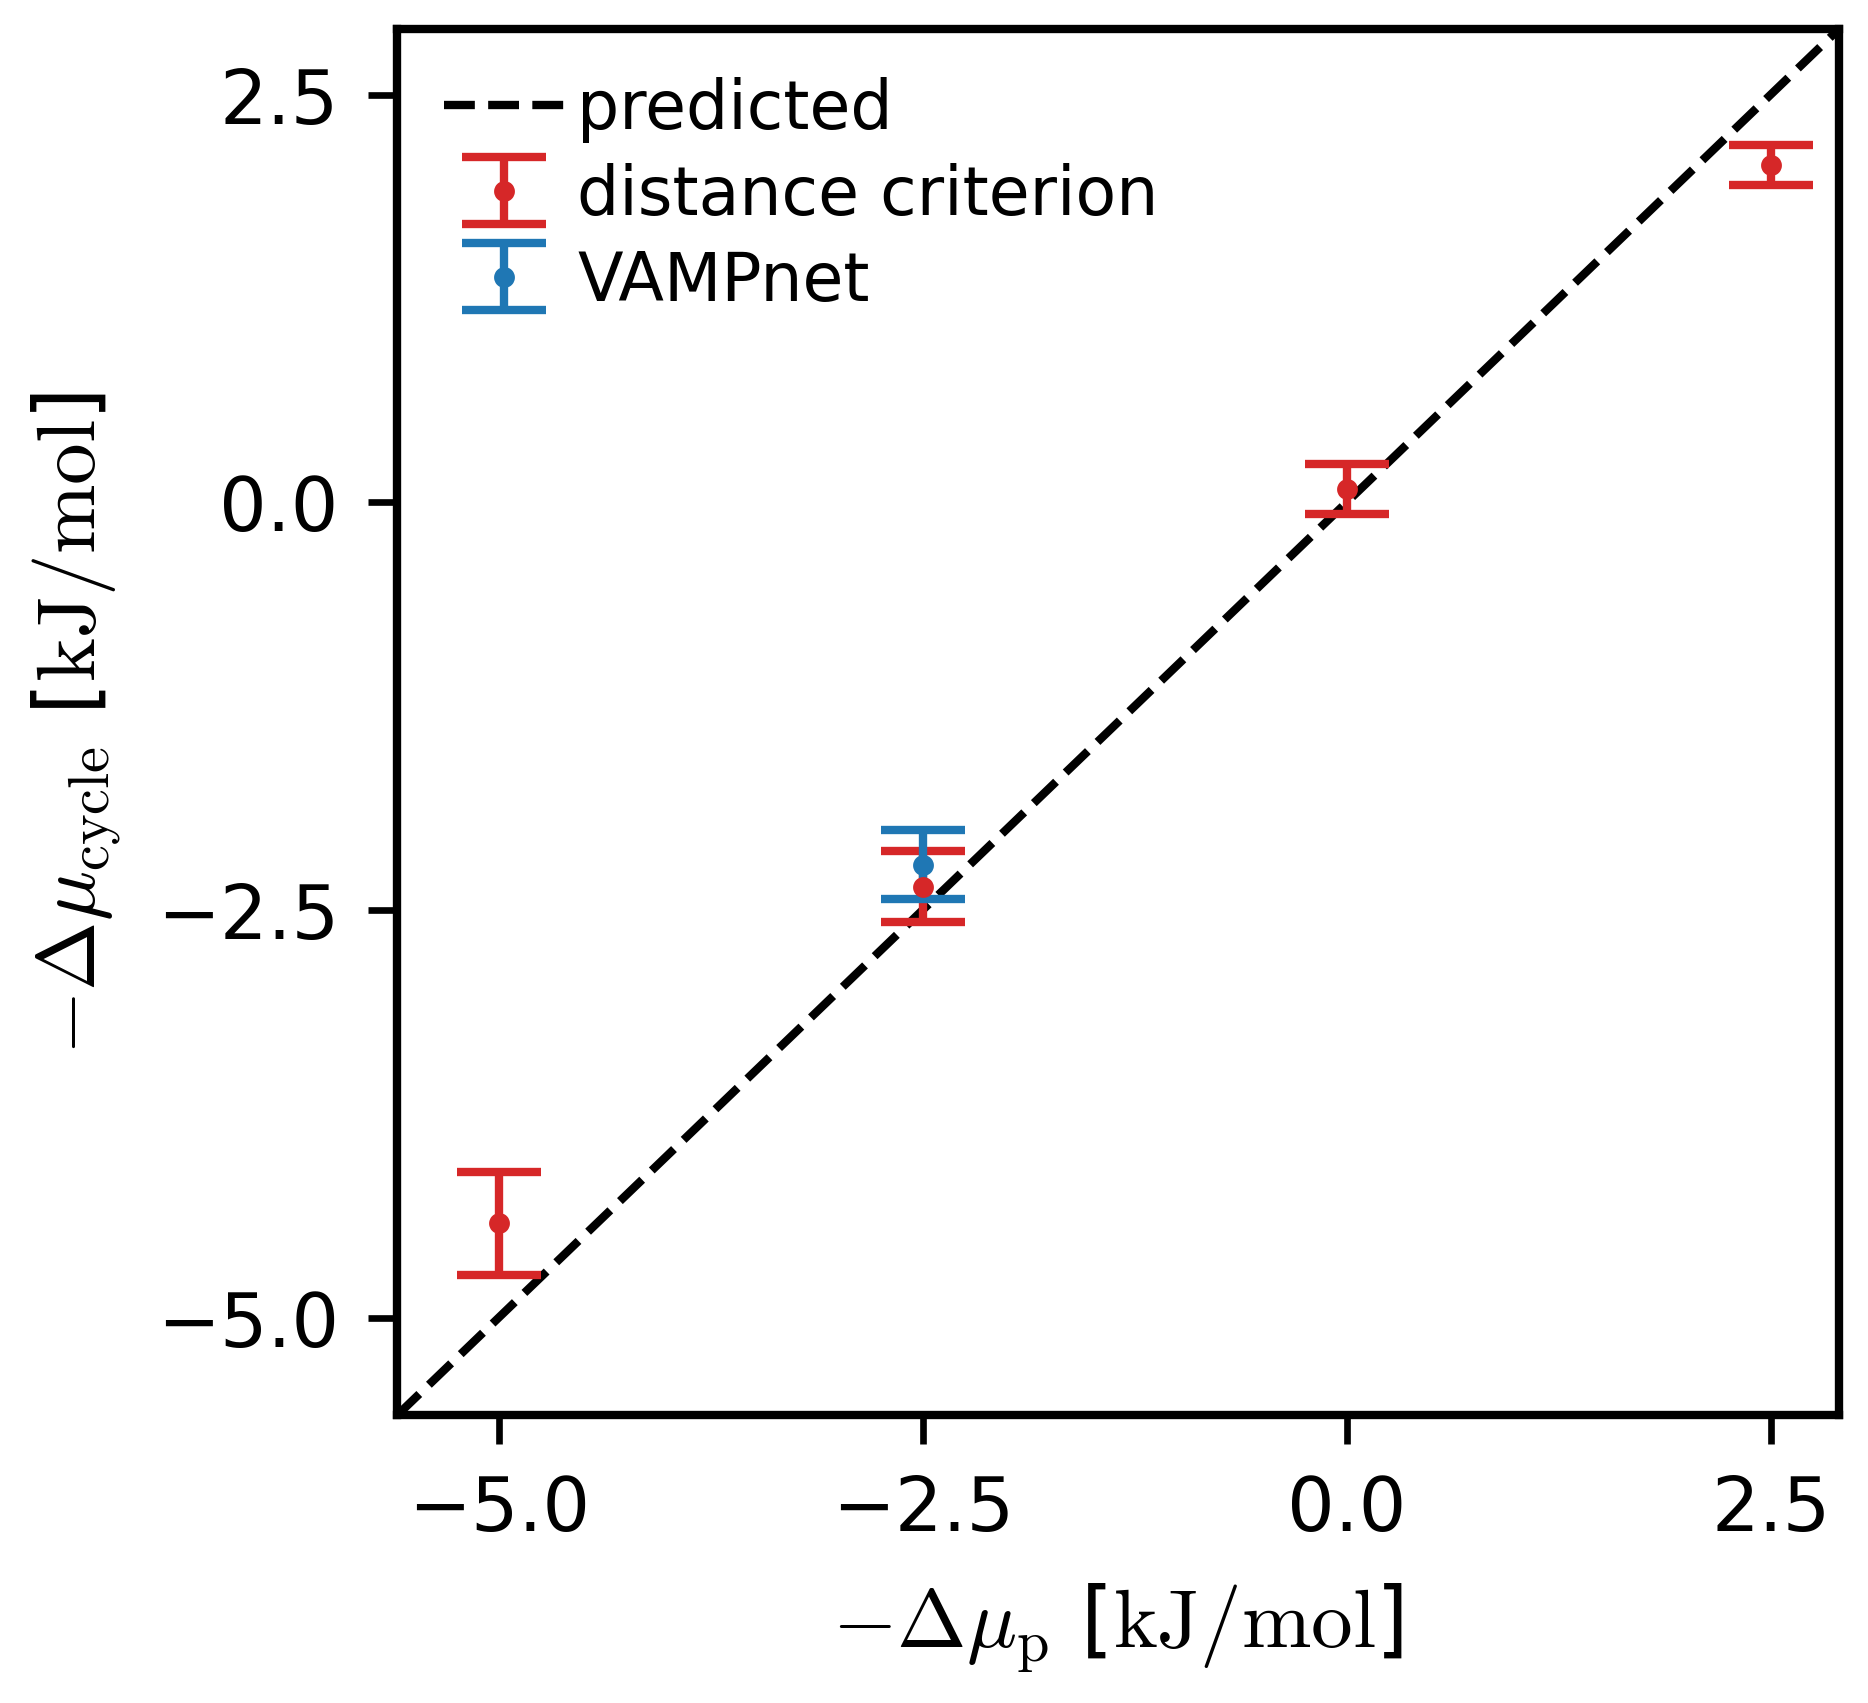

In [37]:
# VAMPnet bound criterion, available for PP3 at dmu_p = +2.5
vampnet_runs = {'pp3': ('+2.5', '_VAMPnet_PP3_CAL3_tlag10')}

plt.figure(figsize=(3.1, 3))
lims = (dmus_arr.min() - 0.6, dmus_arr.max() + 0.4)
plt.plot(lims, lims, '--k', label='predicted')
plt.errorbar(dmus_arr, dmu_results[:, 0], dmu_results[:, 1], fmt='.', color='tab:red', capsize=5, label='distance criterion')

if system in vampnet_runs:
    dmu_v, name_v = vampnet_runs[system]
    dmu_vamp, sigma_dmu_vamp = hpa.msm.dmu_with_error(load_states(system, dmu_v, name_v), 80, kT, pow_bin=12, n_resample=15)
    print('VAMPnet:', dmu_vamp, sigma_dmu_vamp)
    plt.errorbar([-float(dmu_v)], [dmu_vamp], [sigma_dmu_vamp], fmt='.', color='tab:blue', capsize=5, label='VAMPnet')

plt.legend()
plt.xlabel(r'$- \Delta \mu_\mathrm{p}$ [$\mathrm{kJ/mol}$]')
plt.ylabel(r'$- \Delta \mu_\mathrm{cycle}$ [$\mathrm{kJ/mol}$]')
plt.xlim(*lims)
plt.ylim(*lims)
plt.xticks(dmus_arr)
plt.yticks(dmus_arr)
savefig(summary_prefix(system, 'dmu'))

# 3. CK1δ + PP3: 6-state MSM
Cycle 1 → 2 → 3 → 4 → 5 → 6 → 1 (U-free, U-CK1δ, P-CK1δ, P-free, P-PP3, U-PP3).
Expected $\Delta\mu_{cycle} = -\Delta\mu_k + \Delta\mu_p$.

In [38]:
system = 'ck1d_pp3'
dmuk, dmup = '-5', '+2.5'
dmu = f'{dmuk}_{dmup}'
CYCLE6 = [0, 1, 2, 3, 4, 5]

def fig_name(label):
    return file_prefix(path_pl, system, dmu, label)

states = load_states(system, dmu)
print(len(states), 'frames, states', np.unique(states))

1984192 frames, states [0 1 2 3 4 5]


## Implied timescales

100%|█████████████████████████████████████████████████████████████████████| 7/7 [00:00<00:00, 11.25it/s]


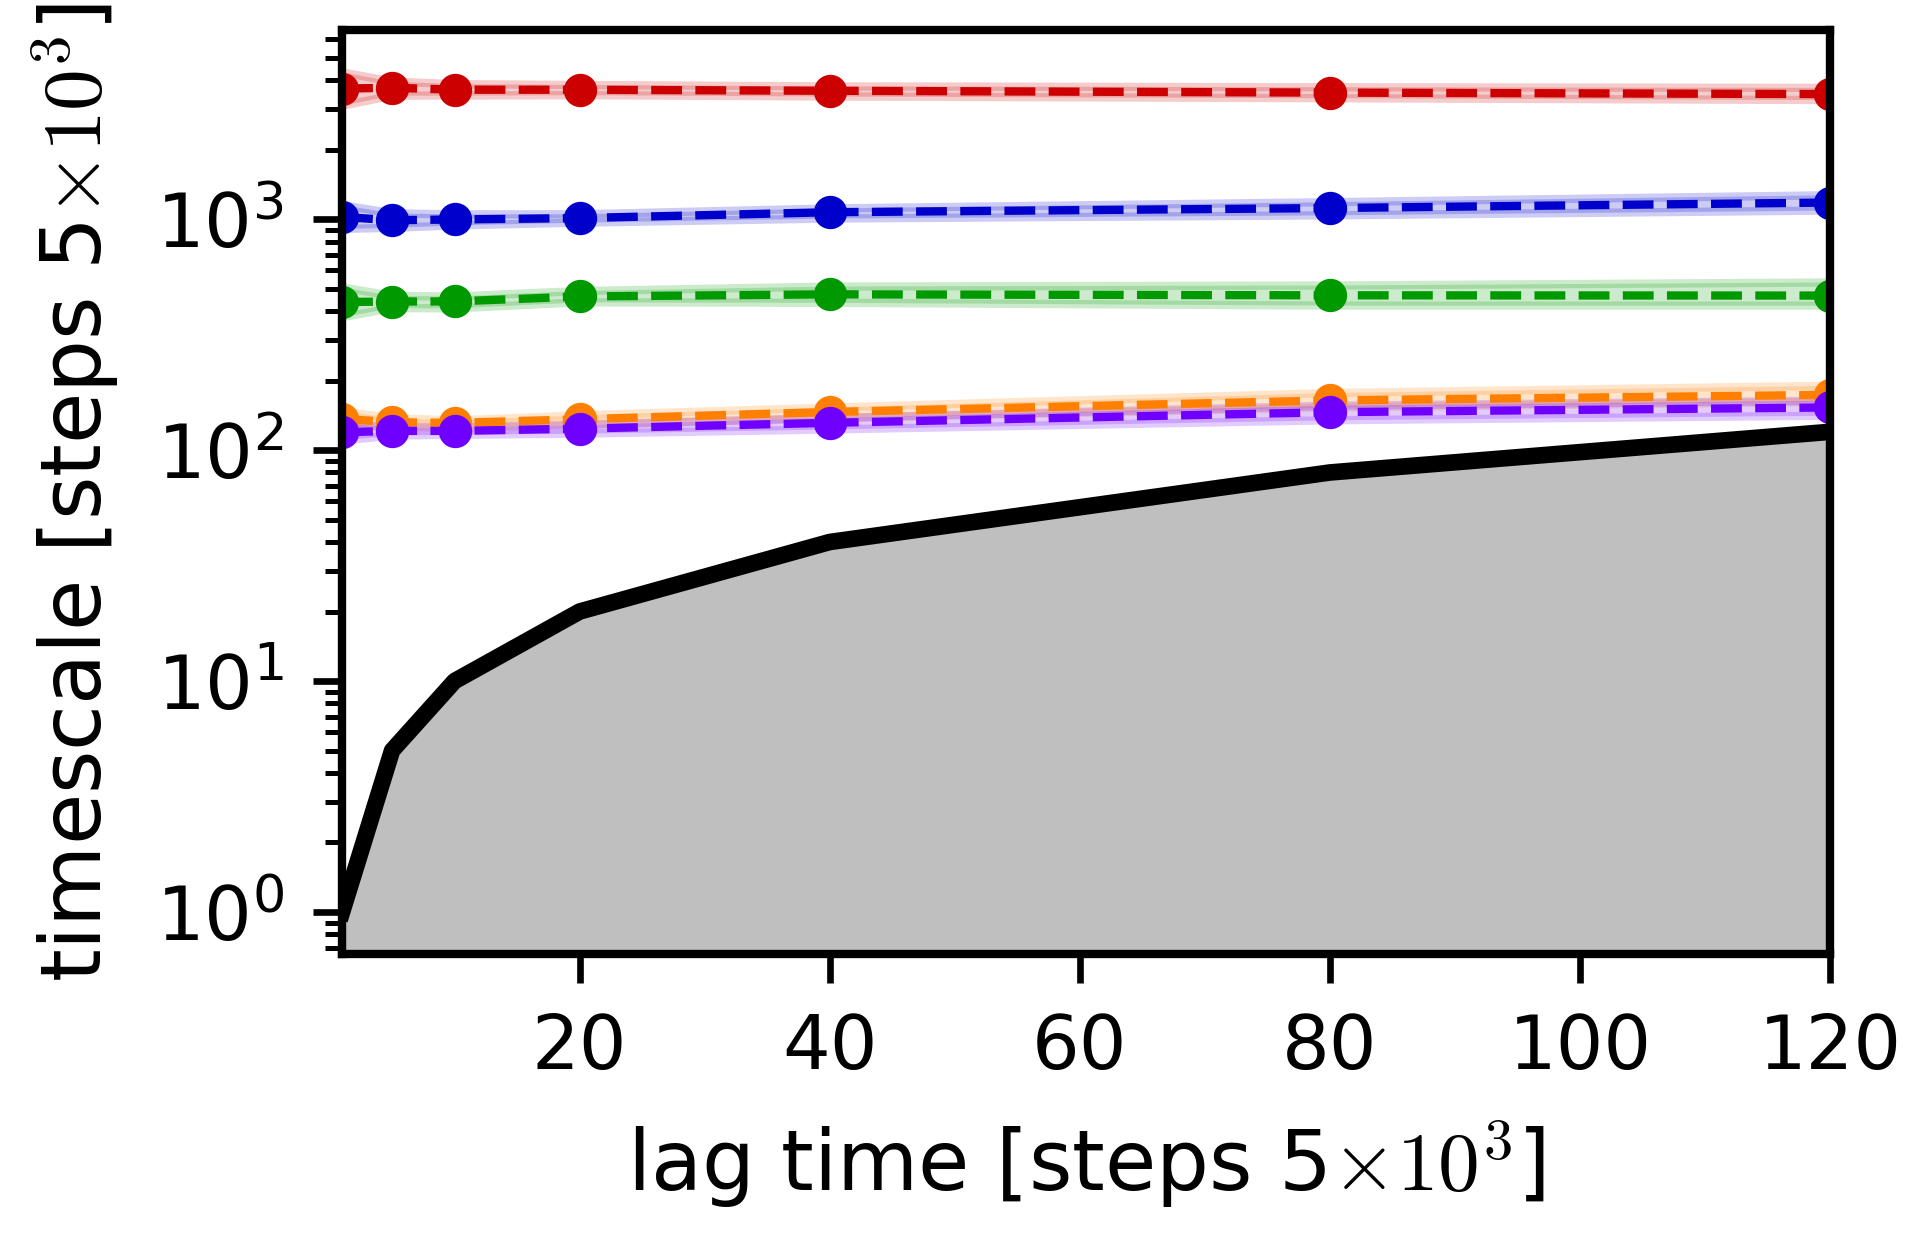

In [85]:
lagtimes = np.array([1, 5, 10, 20, 40, 80, 120])
models = bayesian_msms(states, lagtimes, n_steps=2**12)
plot_its(models, xlim=(1, 120), save=fig_name('its'))

## Chapman-Kolmogorov test

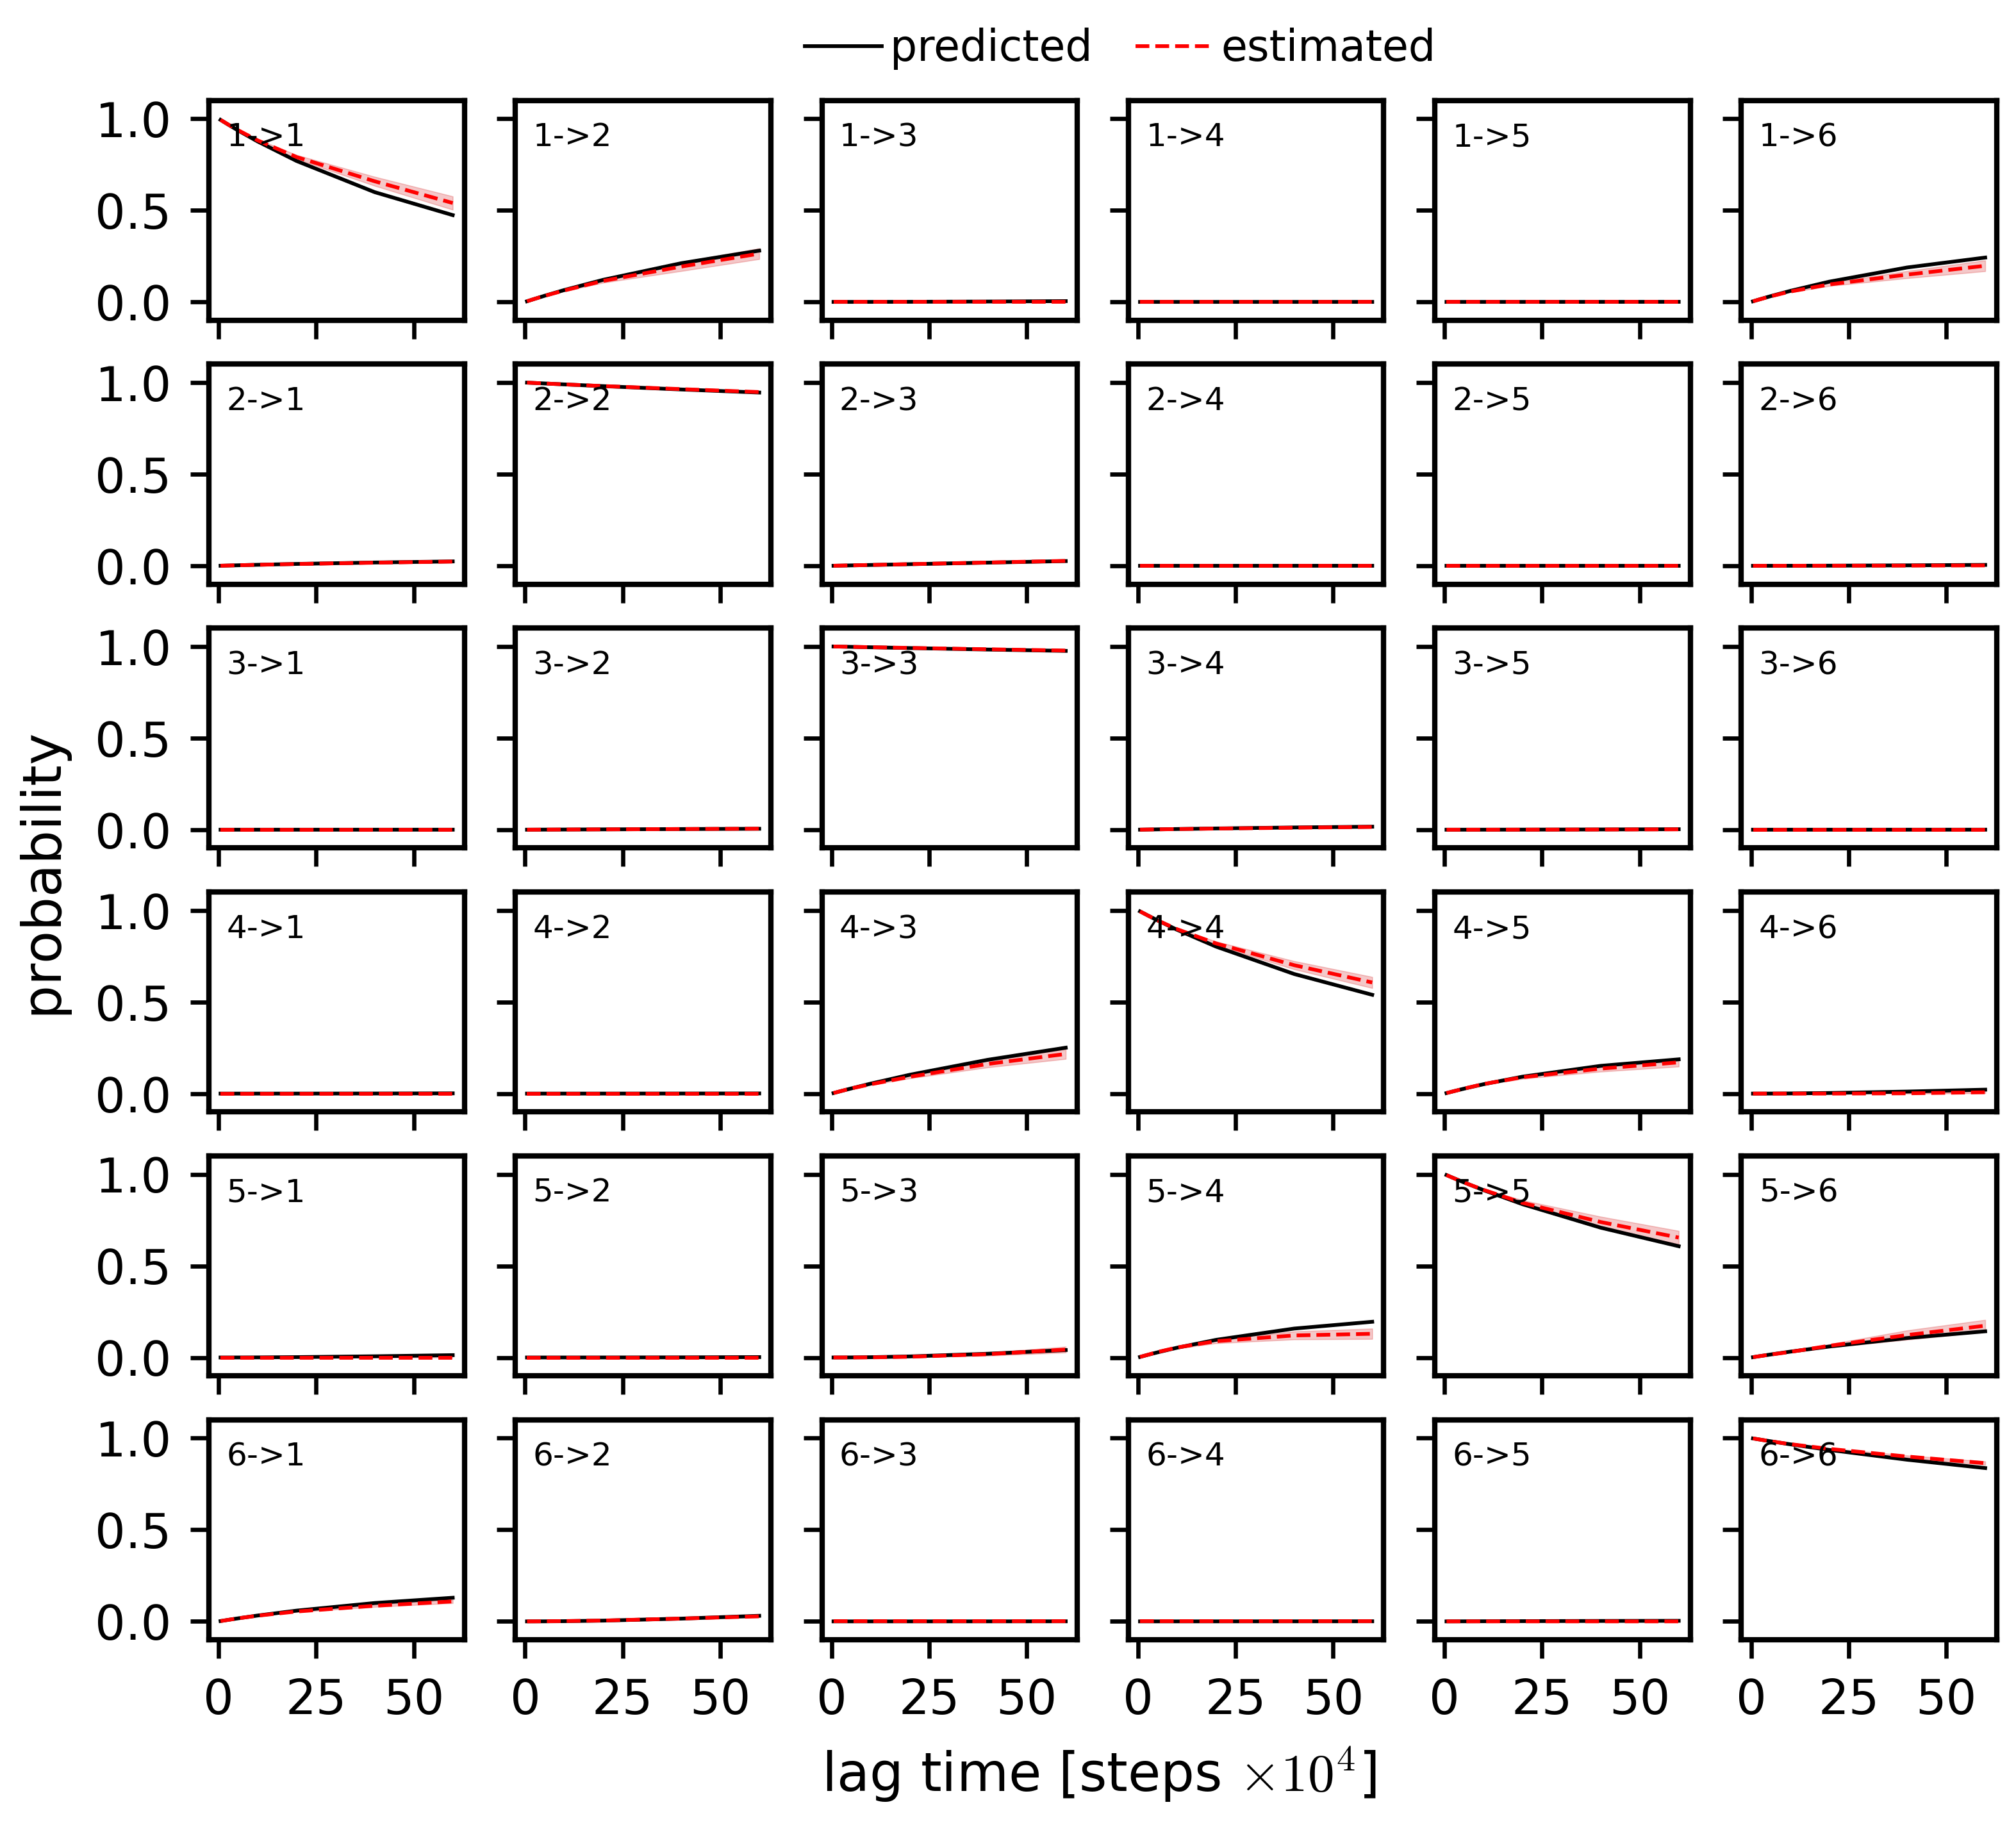

In [86]:
pred_ck, est_ck, est_err_ck = hpa.msm.ck_test(states, lagtimes)
plot_ck_grid(lagtimes * RDUMP / 10, pred_ck, est_ck, est_err_ck, figsize=(6, 5.2),
             xticks=list(np.round(np.array([0, 50, 100]) * RDUMP / 10).astype(int)), legend_loc=(2.3, 4.7),
             save=fig_name('ck-test'))

## $\Delta\mu$ vs lag time

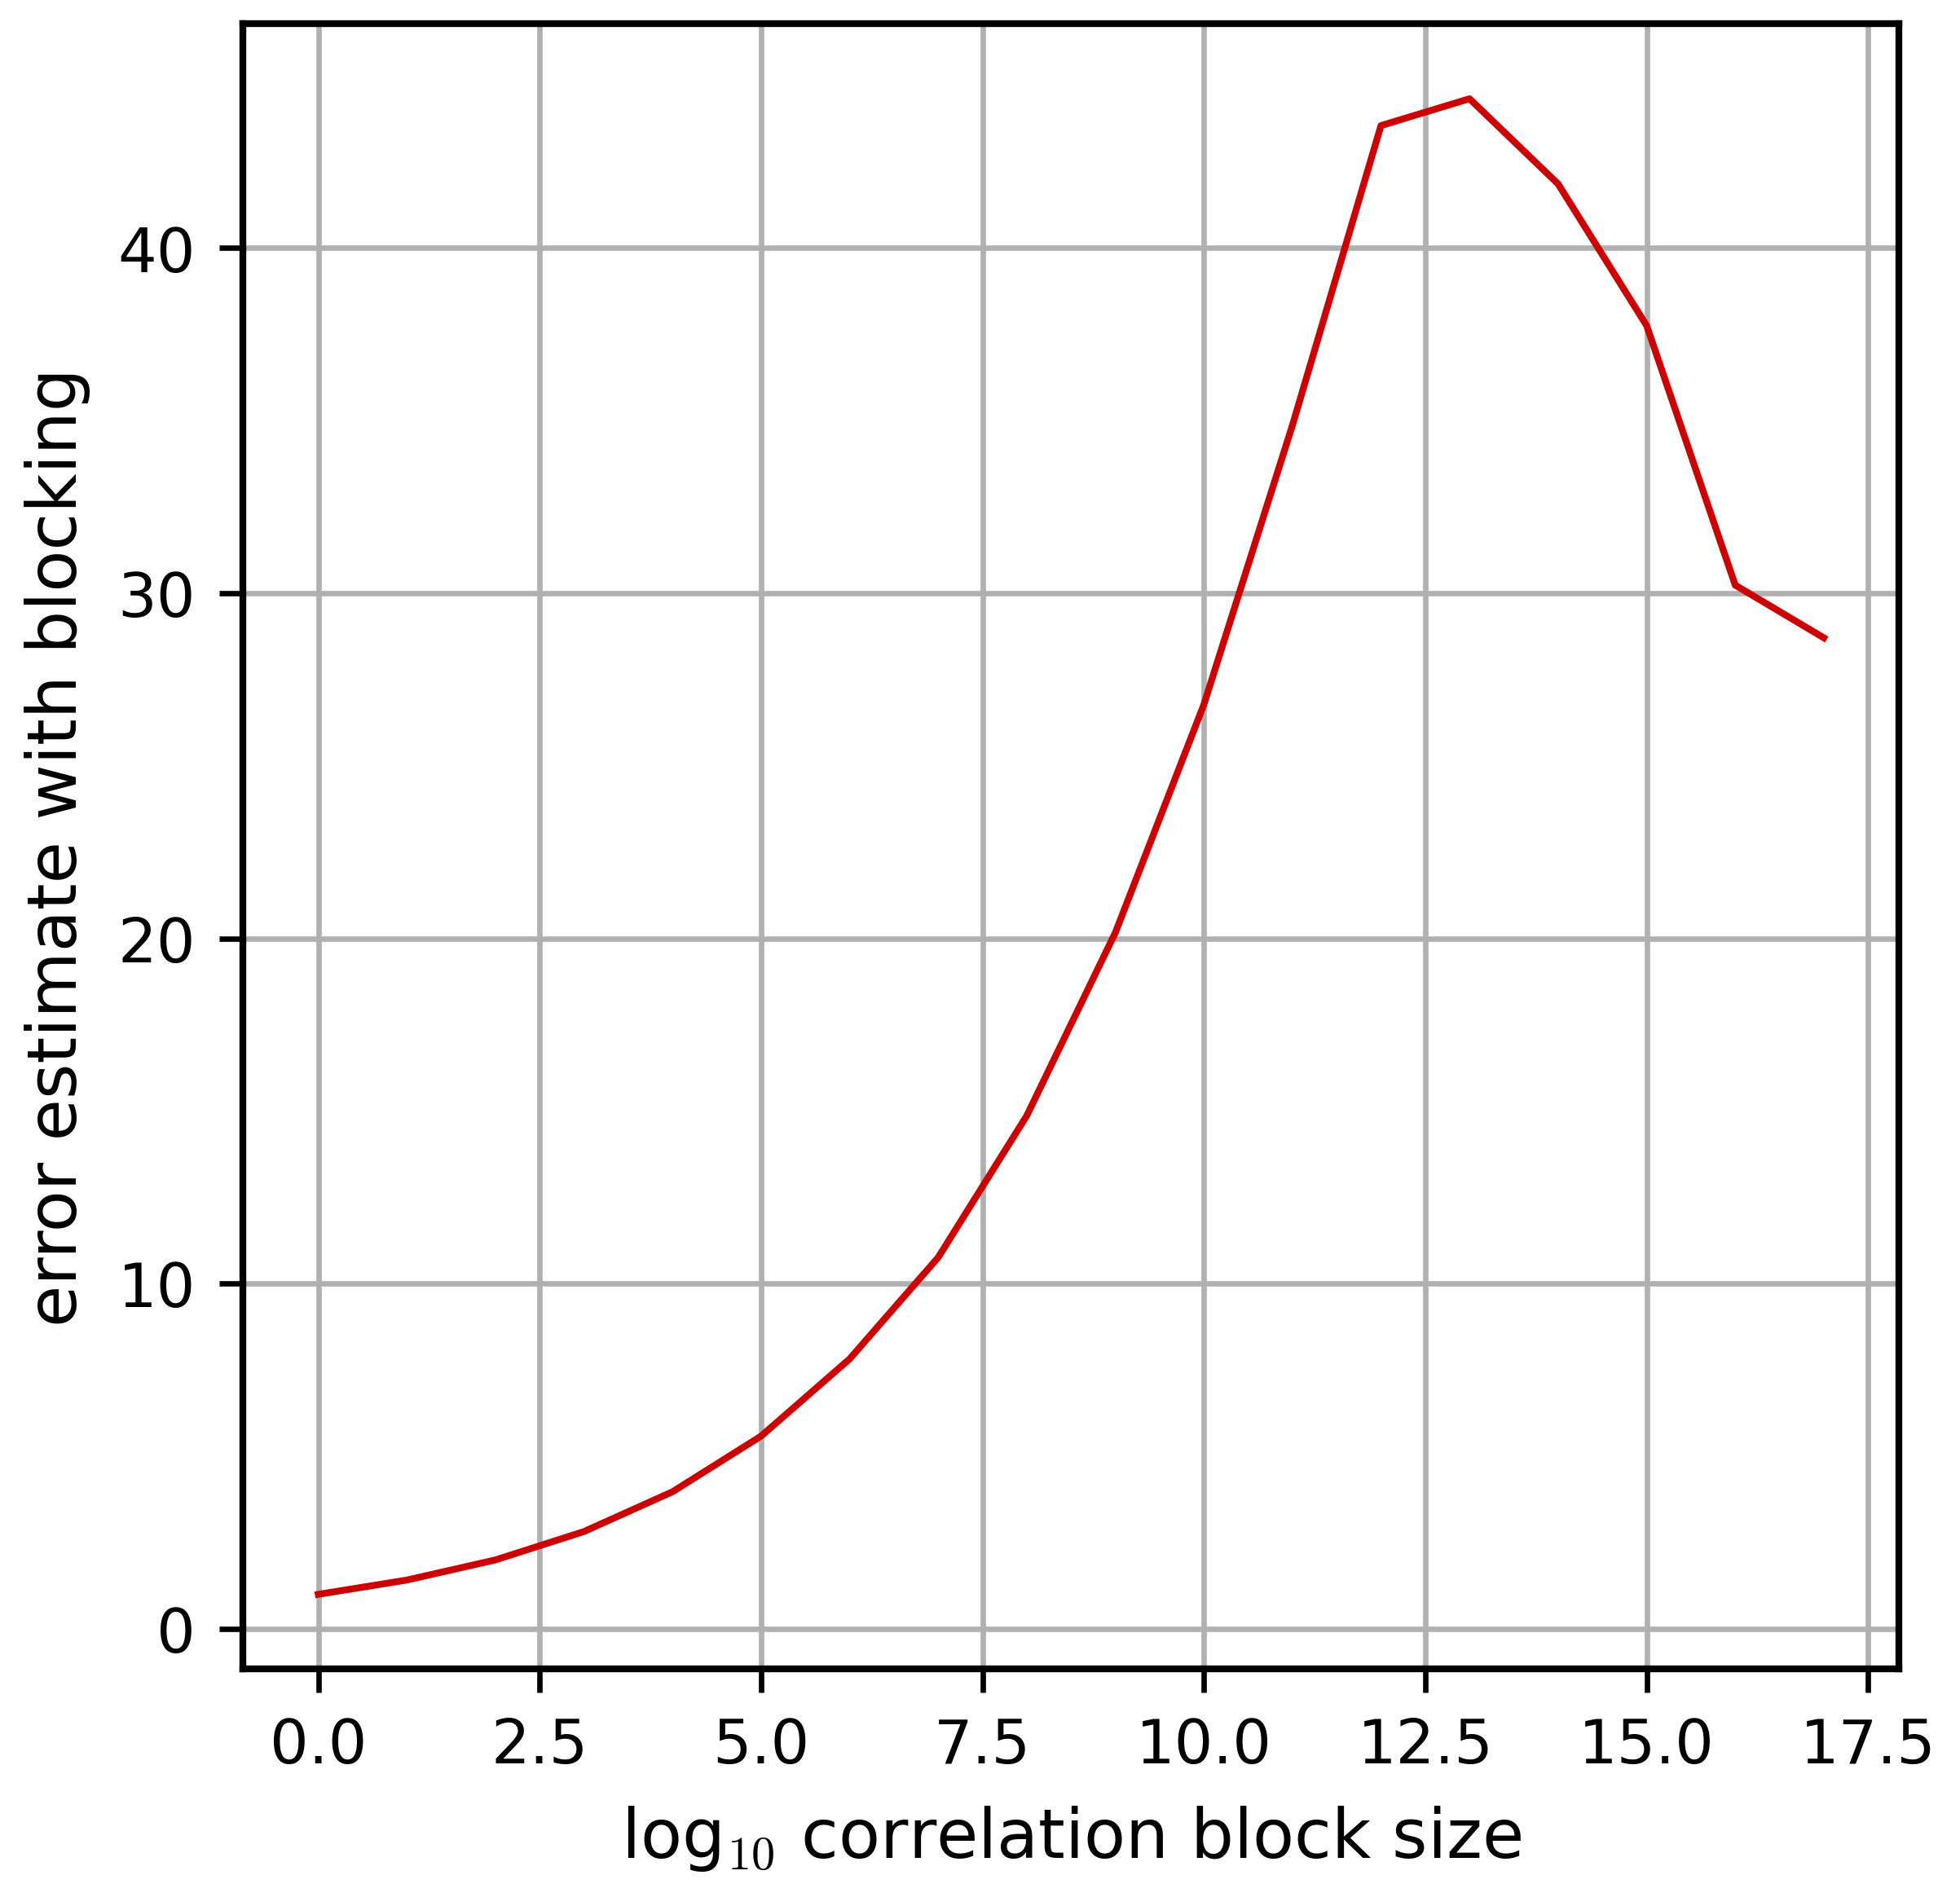

In [87]:
hpa.stats.autocorr_bin(states, 18, 1000)

100%|█████████████████████████████████████████████████████████████████████| 9/9 [00:23<00:00,  2.59s/it]


array([[ 9.93363661,  2.75701647],
       [11.78622145,  6.7905113 ],
       [12.82430038, 19.71327628],
       [13.40502194, 22.31260195],
       [13.9014241 , 11.65498832],
       [14.27475918, 17.17908358],
       [14.57219372, 12.8643771 ],
       [14.8428862 , 28.62566313],
       [15.13568133, 18.57224961]])

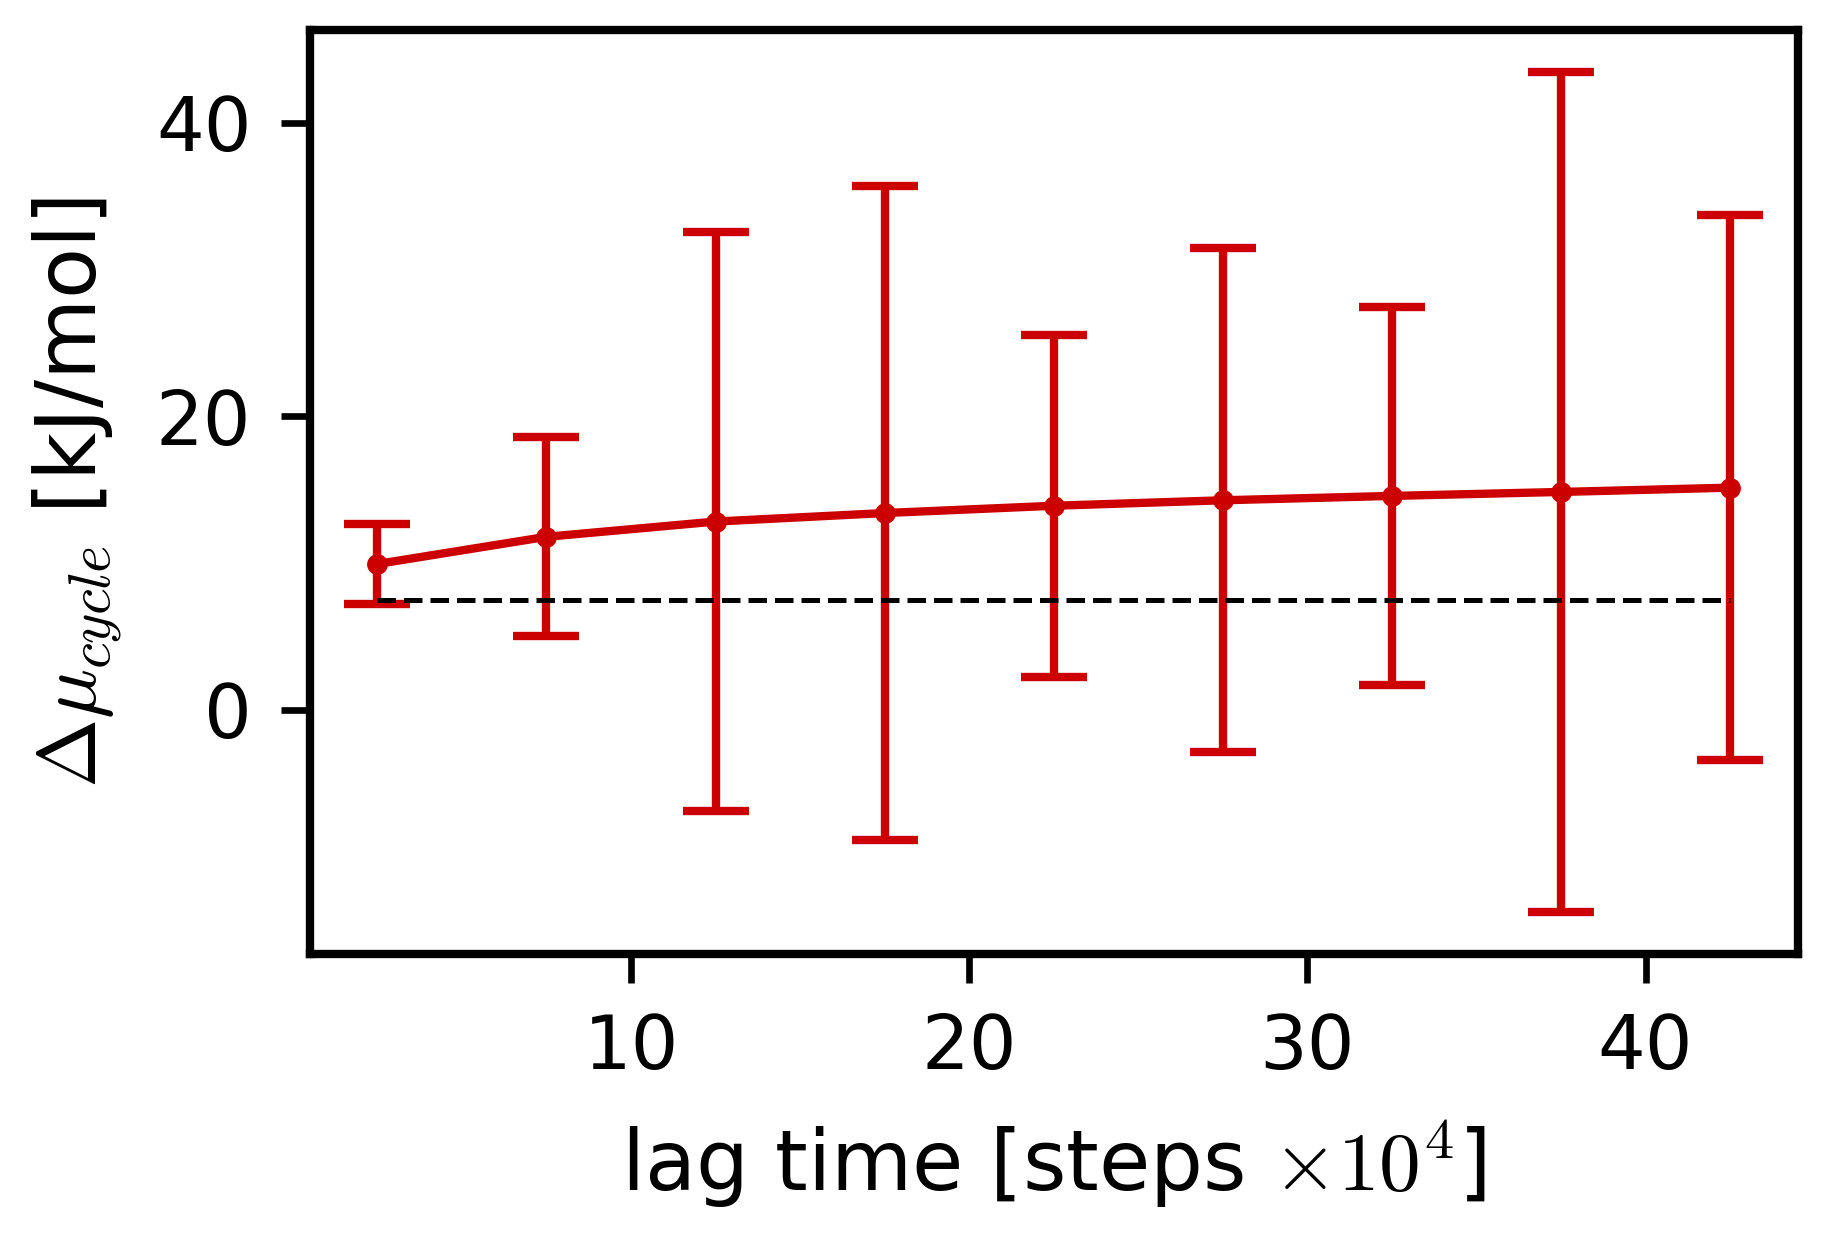

In [88]:
lags_dmu = np.arange(5, 91, 10)
dmus = np.array([hpa.msm.dmu_with_error(states, lag, kT, cycle=CYCLE6, pow_bin=12, n_resample=30) for lag in tqdm(lags_dmu)])
plot_dmu_vs_lag(lags_dmu, dmus, -float(dmuk) + float(dmup), save=fig_name('dmu'))
dmus

## Transition network (lag 70)

array([[6.86237196e-01, 1.74925716e-01, 0.00000000e+00, 0.00000000e+00,
        0.00000000e+00, 1.38837088e-01],
       [1.53256986e-02, 9.68138334e-01, 1.57170861e-02, 0.00000000e+00,
        0.00000000e+00, 8.18881613e-04],
       [0.00000000e+00, 3.16088898e-03, 9.86366432e-01, 9.72710514e-03,
        7.45574179e-04, 0.00000000e+00],
       [0.00000000e+00, 0.00000000e+00, 1.45105346e-01, 7.24945272e-01,
        1.29244495e-01, 7.04887099e-04],
       [0.00000000e+00, 0.00000000e+00, 1.41031077e-02, 1.16114553e-01,
        7.62199491e-01, 1.07582849e-01],
       [7.79226198e-02, 1.27647056e-02, 0.00000000e+00, 0.00000000e+00,
        3.70592816e-05, 9.09275615e-01]])

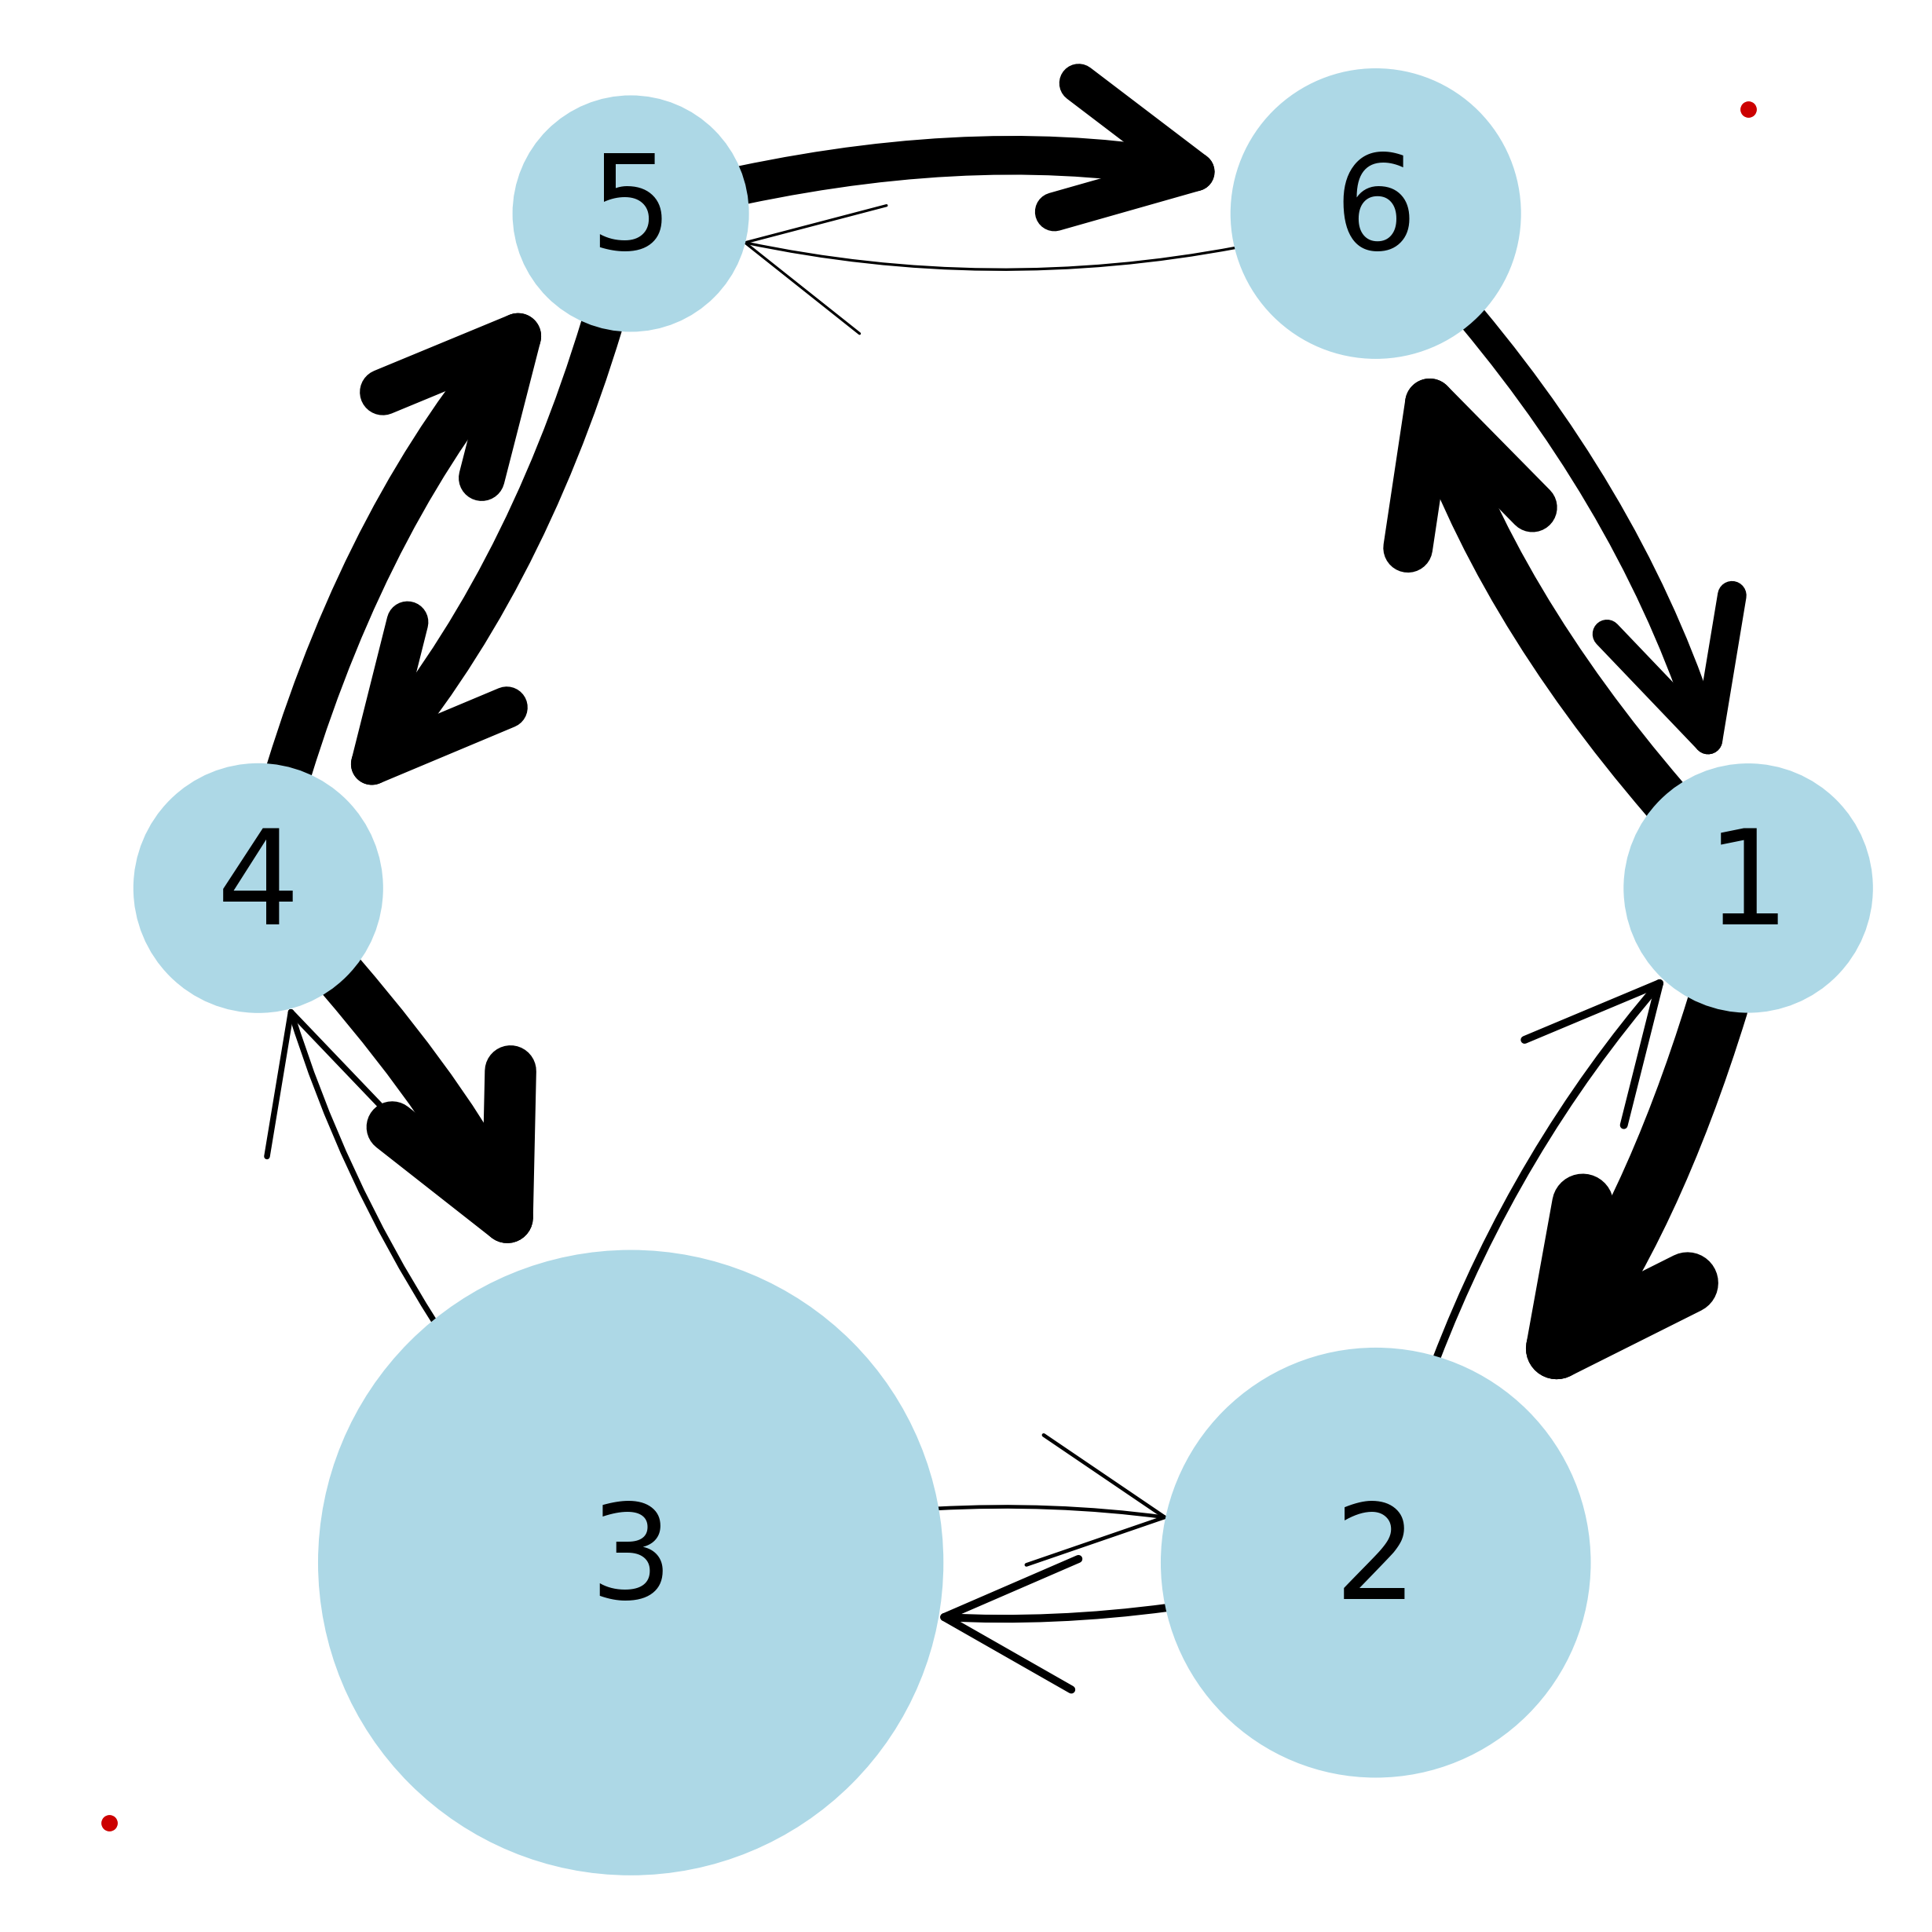

In [89]:
counts = markov.TransitionCountEstimator(lagtime=70, count_mode='effective').fit_fetch(states)
msm = markov.msm.BayesianMSM(n_samples=10000, n_steps=2**8, reversible=False).fit_fetch(counts)
tr_mat = msm.gather_stats('transition_matrix').mean
st_distr = msm.gather_stats('stationary_distribution').mean

plot_cycle_6states(tr_mat, st_distr, save=fig_name('cycle_6states'))
tr_mat

## Dependence on $(\Delta\mu_k, \Delta\mu_p)$ (lag 70)

In [39]:
system = 'ck1d_pp3'

# x position of each (dmu_k, dmu_p) pair in the plots
x_pairs = {'0_0': 0, '-5_0': 5, '-5_+2.5': 7.5, '-10_0': 10}
x = list(x_pairs.values())
xticklabels = ['(0,0)', '(5,0)', '(5,2.5)', '(10,0)']

states_pairs = {pair: load_states(system, pair) for pair in tqdm(x_pairs)}


100%|█████████████████████████████████████████████████████████████████████| 4/4 [00:00<00:00, 27.59it/s]


In [41]:
edges = [hpa.msm.edge_dmus_bootstrap(st, 70, kT, cycle=CYCLE6, pow_bin=12, n_resample=15) for st in tqdm(states_pairs.values())]
edge_dmu = np.array([e for e, _ in edges])
edge_err = np.array([err for _, err in edges])





  0%|                                                                             | 0/4 [00:00<?, ?it/s]

 25%|█████████████████▎                                                   | 1/4 [00:07<00:23,  7.79s/it]

 50%|██████████████████████████████████▌                                  | 2/4 [00:16<00:16,  8.19s/it]

 75%|███████████████████████████████████████████████████▊                 | 3/4 [00:23<00:07,  7.84s/it]

100%|█████████████████████████████████████████████████████████████████████| 4/4 [00:34<00:00,  8.62s/it]


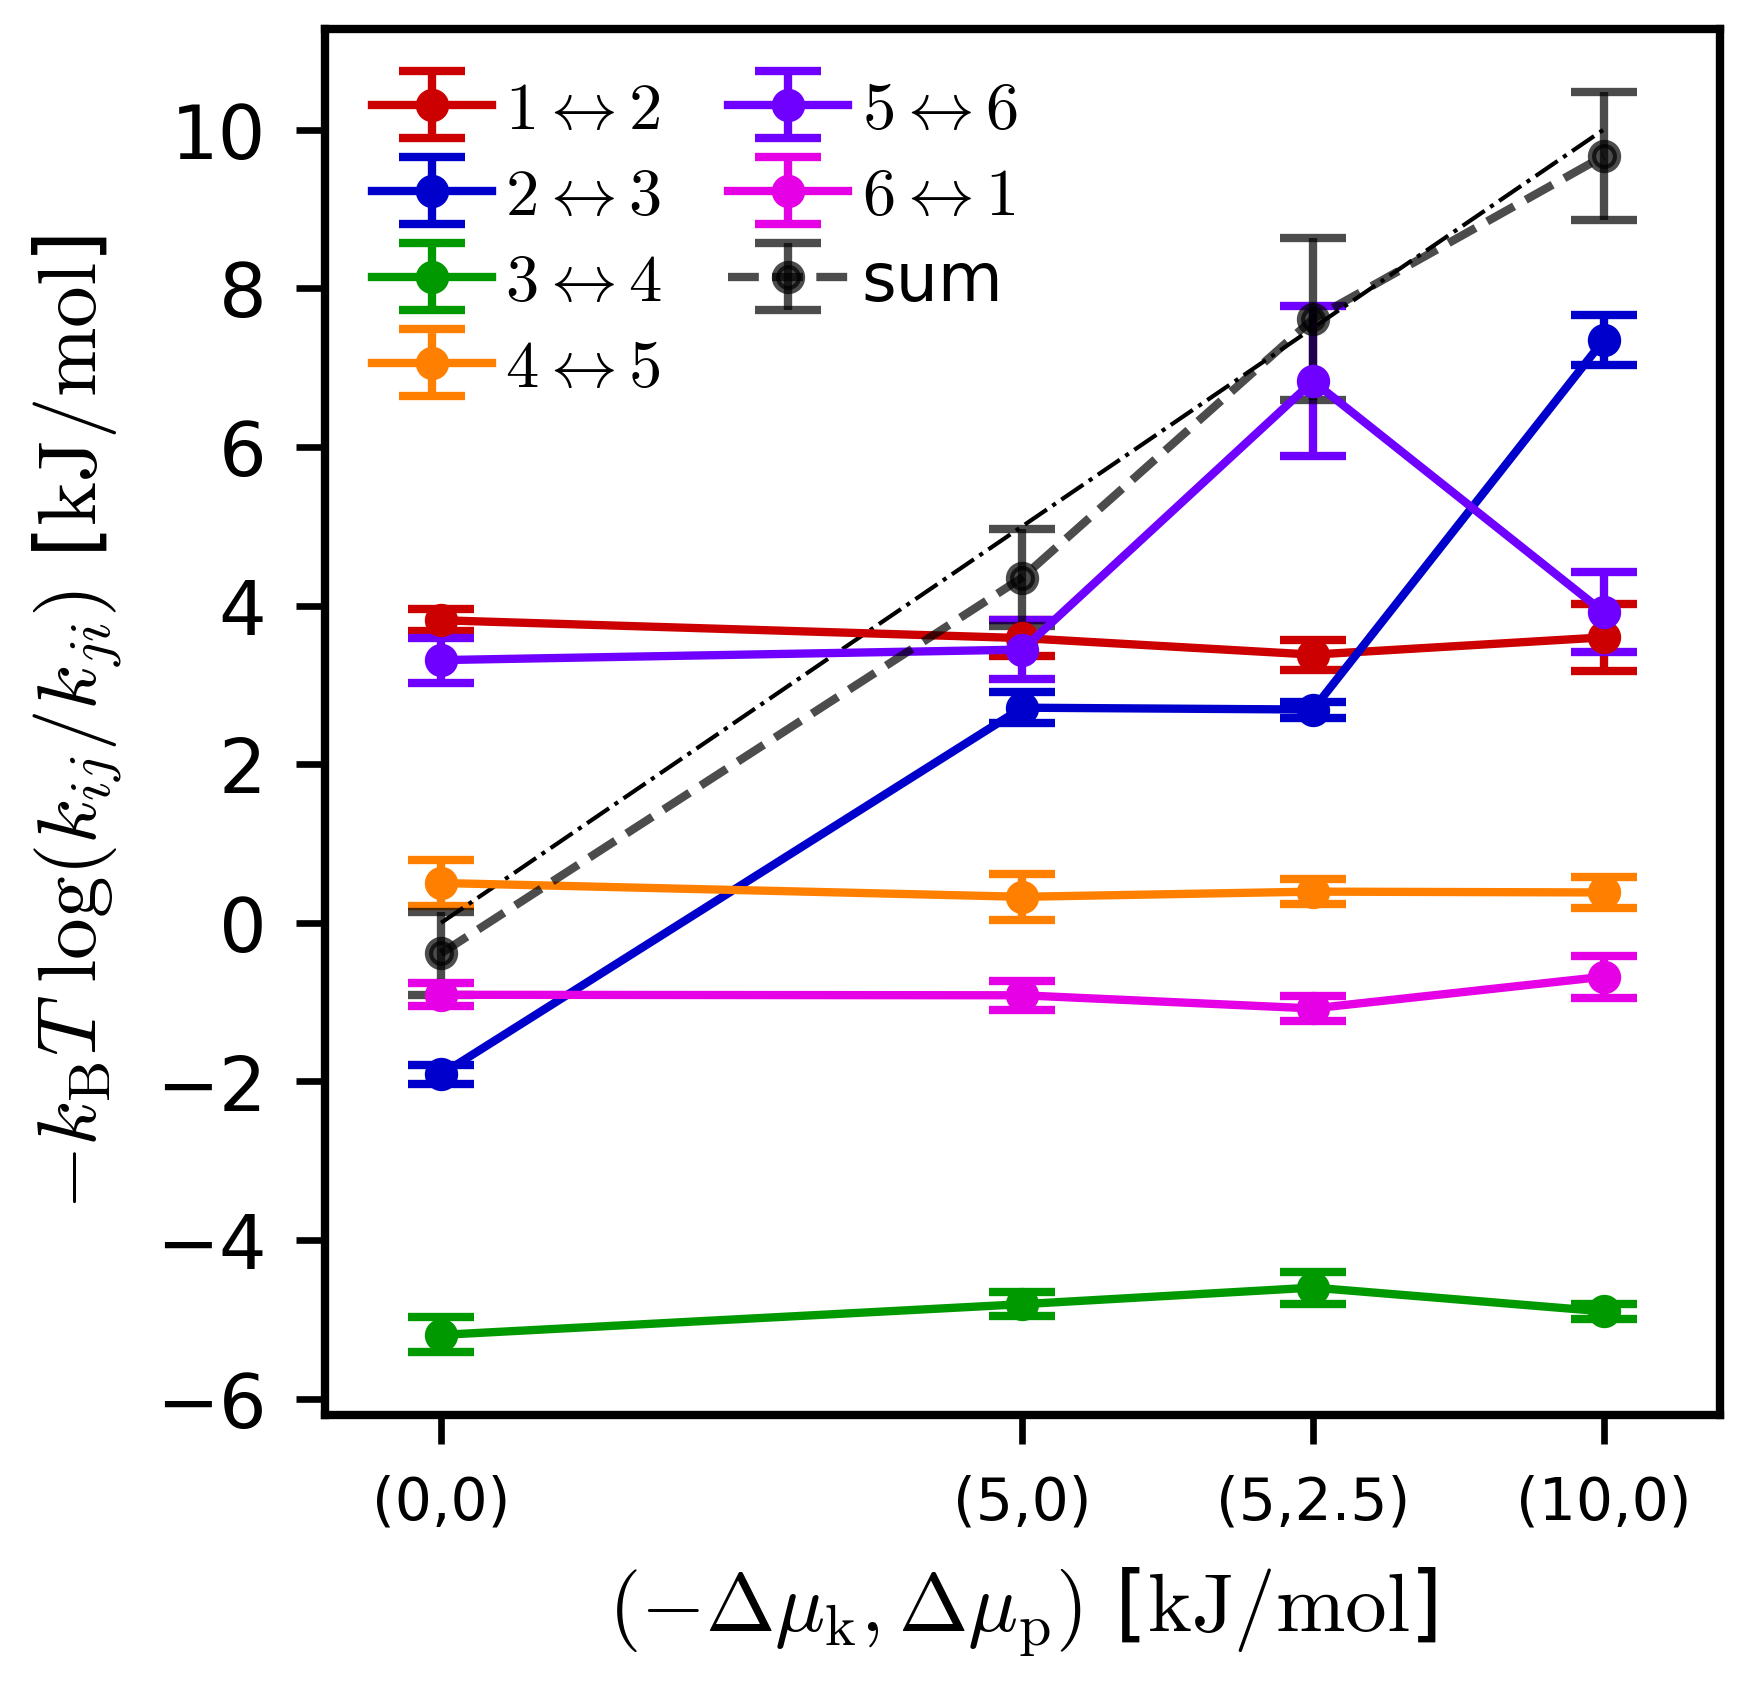

In [42]:
plt.figure(figsize=(3, 3))
for k in range(6):
    plt.errorbar(x, edge_dmu[:, k], edge_err[:, k], capsize=4, fmt='o-', label=rf'${k+1} \leftrightarrow {(k+1) % 6 + 1}$')
plt.errorbar(x, edge_dmu.sum(axis=1), np.sqrt(np.sum(edge_err**2, axis=1)), capsize=4, fmt='o--k', alpha=0.7, label='sum')
plt.plot([0, 10], [0, 10], '-.k', lw=0.5)
plt.xticks(x, xticklabels, fontsize=7)
plt.xlabel(r'$(-\Delta \mu_\mathrm{k}, \Delta \mu_\mathrm{p})$ [$\mathrm{kJ/mol}$]')
plt.ylabel(r'$- k_\mathrm{B } T~ \log(k_{ij}/k_{ji})$ [$\mathrm{kJ/mol}$]')
plt.legend(ncols=2)
plt.xlim(-1, 11)
savefig(summary_prefix(system, 'dmu_contributions'))

In [43]:
dmu_results = np.array([hpa.msm.dmu_with_error(st, 70, kT, cycle=CYCLE6, pow_bin=12, n_resample=15)
                        for st in tqdm(states_pairs.values())])




  0%|                                                                             | 0/4 [00:00<?, ?it/s]

 25%|█████████████████▎                                                   | 1/4 [00:07<00:23,  7.74s/it]

 50%|██████████████████████████████████▌                                  | 2/4 [00:16<00:16,  8.12s/it]

 75%|███████████████████████████████████████████████████▊                 | 3/4 [00:23<00:07,  7.90s/it]

100%|█████████████████████████████████████████████████████████████████████| 4/4 [00:34<00:00,  8.52s/it]


array([[-0.38543723,  0.78753347],
       [ 4.35279922,  0.62418371],
       [ 7.61227455,  0.90444508],
       [ 9.66577088,  0.90070528]])

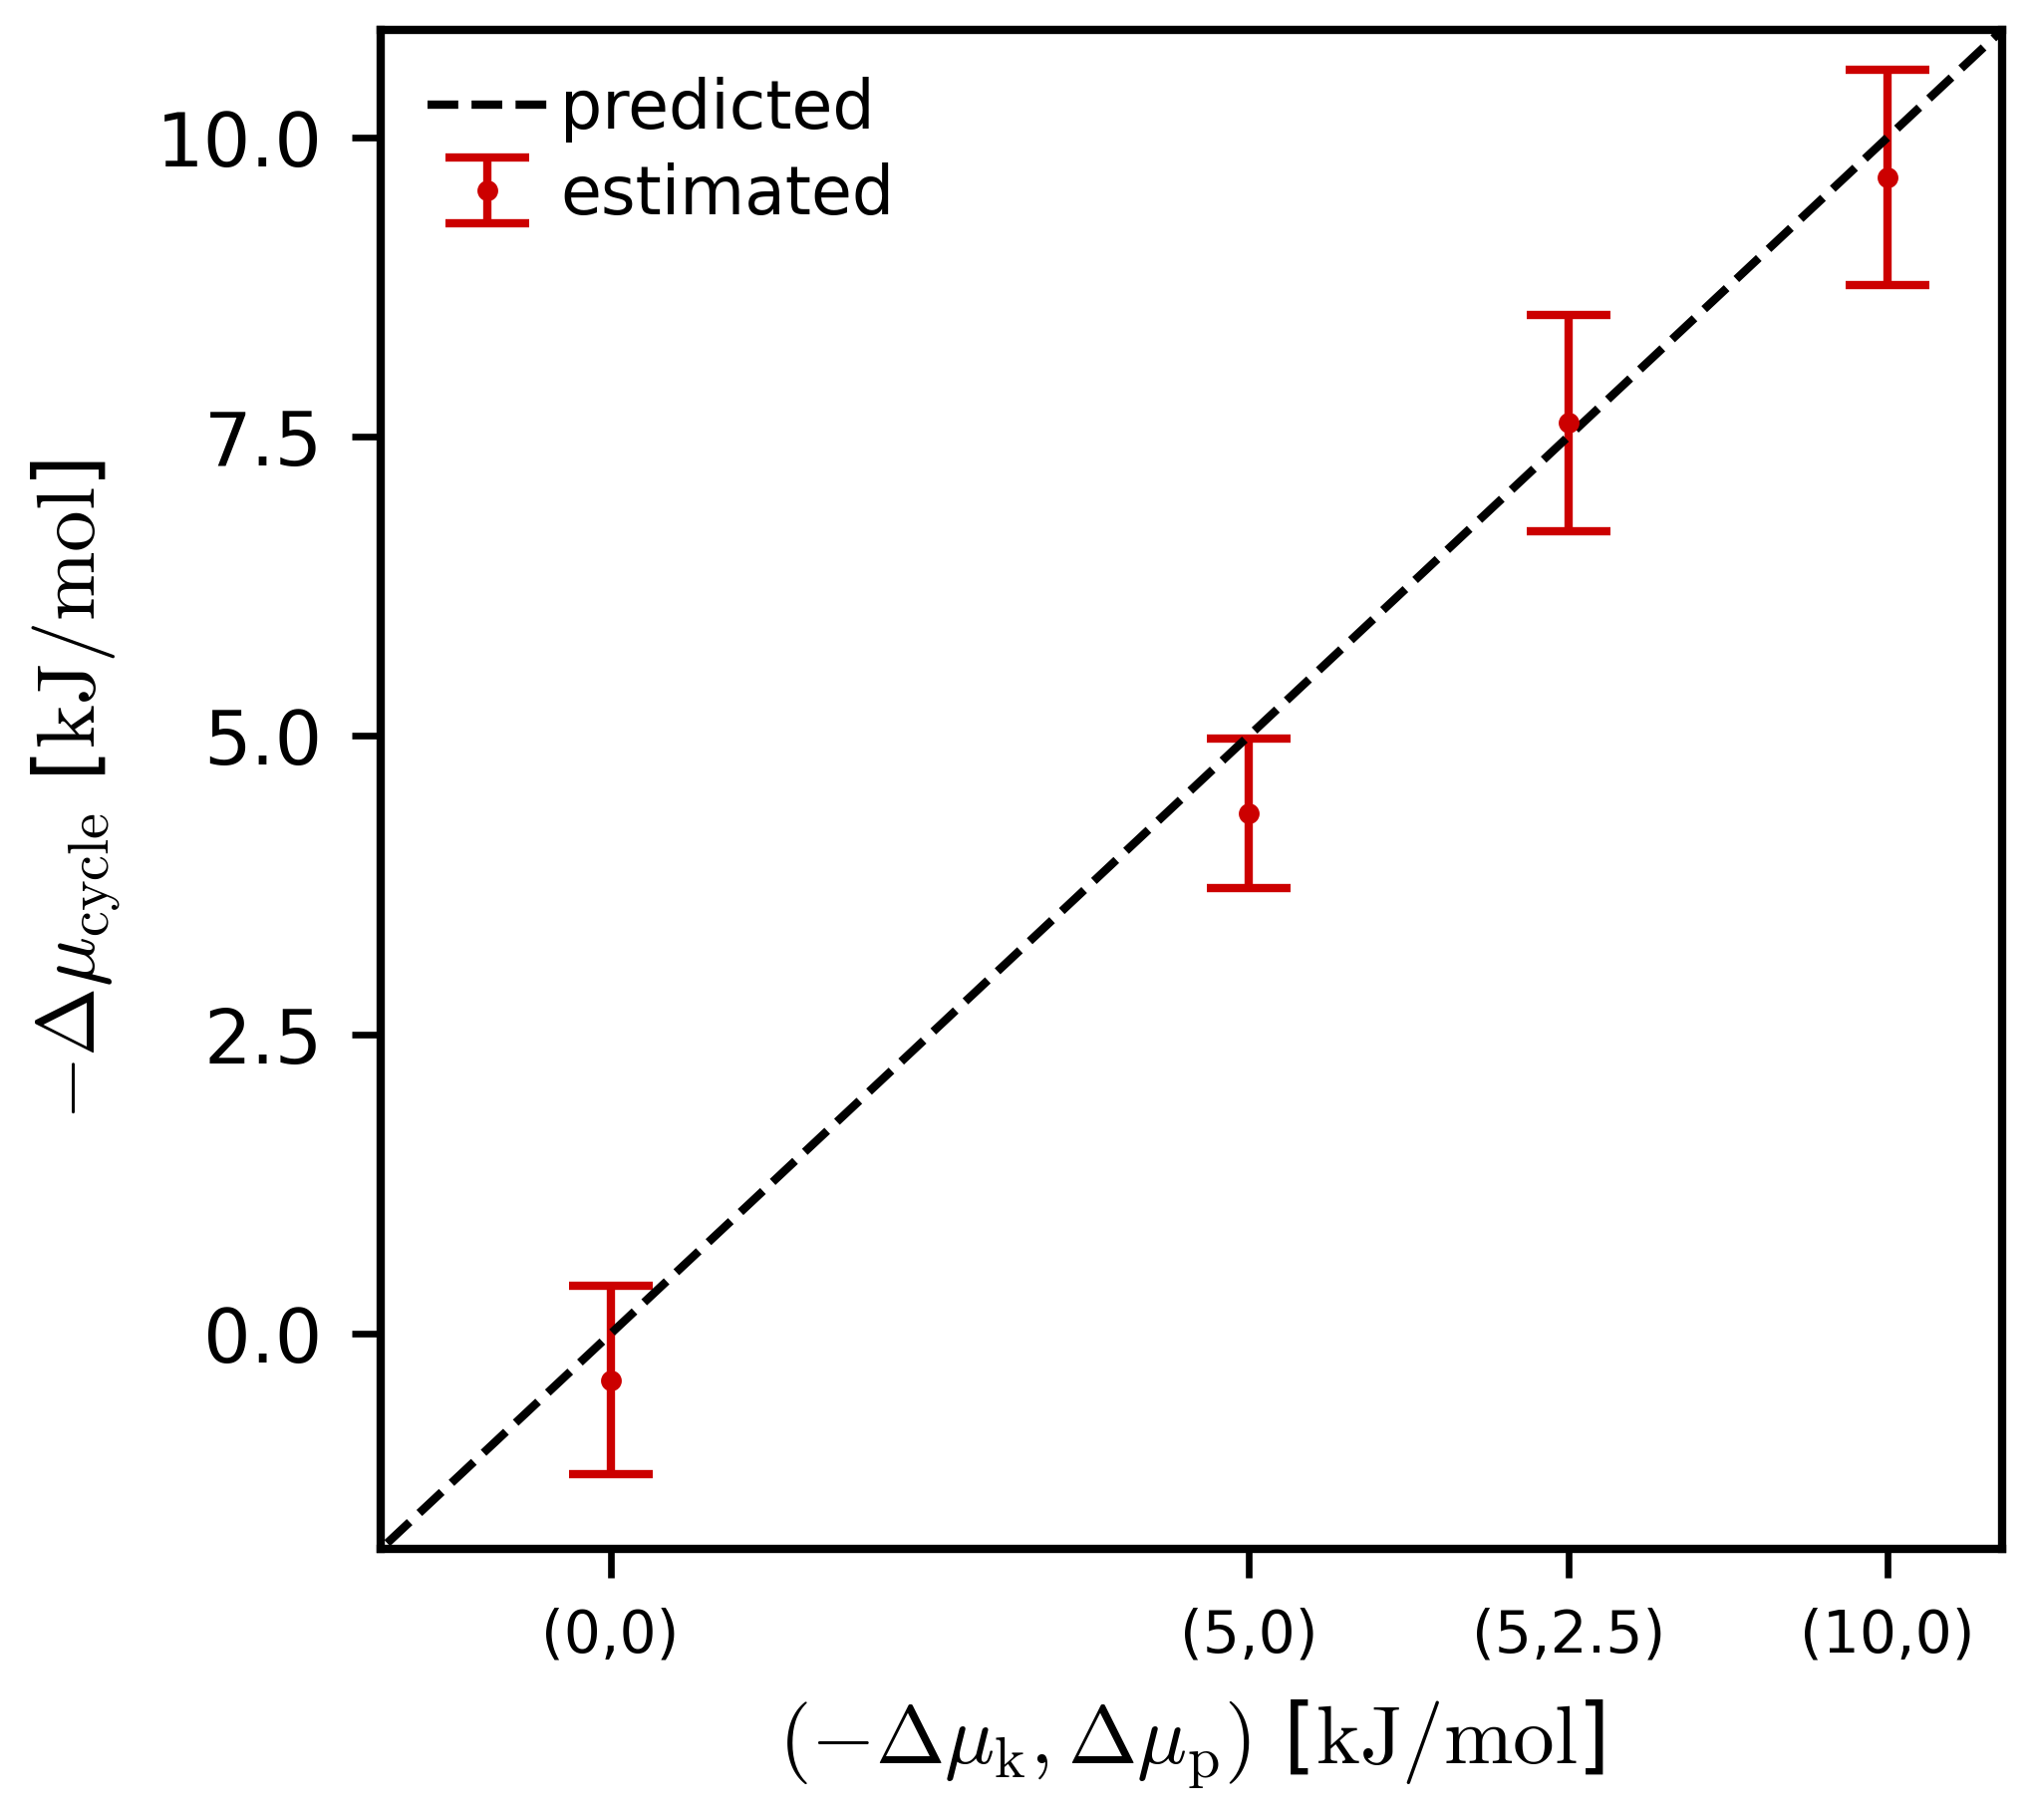

In [44]:
plt.figure(figsize=(3.5, 3.3))
plt.errorbar(x, dmu_results[:, 0], dmu_results[:, 1], fmt='.', capsize=5, label='estimated')
plt.plot([-2, 11], [-2, 11], '--k', label='predicted')
plt.legend()
plt.xlabel(r'$(-\Delta \mu_\mathrm{k}, \Delta \mu_\mathrm{p})$ [$\mathrm{kJ/mol}$]')
plt.ylabel(r'$- \Delta \mu_\mathrm{cycle}$ [$\mathrm{kJ/mol}$]')
plt.xlim(-1.8, 10.9)
plt.ylim(-1.8, 10.9)
plt.xticks(x, xticklabels, fontsize=7)
plt.yticks([0, 2.5, 5, 7.5, 10])
savefig(summary_prefix(system, 'dmu'))
dmu_results